# Rolling Brier: windows count EVENTS

Each event's Brier is the mean of its fight-level squared errors. Rolling windows
then average these event scores with equal event weights. `WINDOW=100` means
100 events, not fights. Expected Brier averages p(1-p) within event before rolling.
A 1-event window is the unsmoothed event score. No correlation lag shifts are used.

Earlier fight-window outputs were cleared because their results do not apply to
this definition. Forecast/search cells have been updated but must be rerun to
obtain event-window results. The original notebook is backed up separately.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Allow Run All from the repository root or this notebook's directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "ufc_betting").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from inside the SportsBetting repository")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from ufc_betting.config import settings

FIT_MODE = "trainval"    # Combined train + validation fitting cohort
MODEL_TYPE = "open"      # "open", "close1", or "close2"
ODDS_TYPE = "open"       # Vegas market to compare
PROBABILITY_MODEL = "inference"
WINDOW = 100

prediction_path = (settings.data_dir / "model_comparisons" / "lr_open_close"
                   / "report_predictions" / FIT_MODE / MODEL_TYPE / PROBABILITY_MODEL
                   / f"train_with_{ODDS_TYPE}.csv")
train = pd.read_csv(prediction_path)
if not train.probability_model.eq(PROBABILITY_MODEL).all():
    raise ValueError("Prediction probability source does not match configuration")
train["date"] = pd.to_datetime(train.date, errors="raise")
order = ["date"] + (["bout_position"] if "bout_position" in train else [])
order += ["fighter_red", "fighter_blue"]
train = train.sort_values(order, kind="stable").reset_index(drop=True)
red_price = pd.to_numeric(train[f"dec_{ODDS_TYPE}_red"], errors="coerce")
blue_price = pd.to_numeric(train[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
model = pd.to_numeric(train.proba_red, errors="coerce")
valid = (train.winner.isin([0, 1]) & model.between(0, 1) & train.date.notna()
         & np.isfinite(red_price) & np.isfinite(blue_price)
         & red_price.gt(1) & blue_price.gt(1))
vegas = (1 / red_price) / (1 / red_price + 1 / blue_price)
fight_scores = train.loc[valid, ["date", "fighter_red", "fighter_blue", "winner"]].copy()
fight_scores["model_brier"] = (model.loc[valid] - fight_scores.winner) ** 2
fight_scores["vegas_brier"] = (vegas.loc[valid] - fight_scores.winner) ** 2
fight_scores["vegas_expected_brier"] = vegas.loc[valid] * (1-vegas.loc[valid])
# Every rolling window below operates on one equally weighted score per event.
scores = fight_scores.groupby('date',sort=True)[['model_brier','vegas_brier','vegas_expected_brier']].mean().reset_index()
scores['vegas_excess_brier'] = scores.vegas_brier-scores.vegas_expected_brier
if len(scores)<WINDOW:raise ValueError(f'Need at least {WINDOW} events')
scores['rolling_model']=scores.model_brier.rolling(WINDOW,min_periods=WINDOW).mean()
scores['rolling_vegas']=scores.vegas_brier.rolling(WINDOW,min_periods=WINDOW).mean()
print(f'Source: {prediction_path}')
print(f'{len(fight_scores)} fights aggregated into {len(scores)} events. Window: {WINDOW} EVENTS, equal event weights.')


Source: C:\Users\jcmar\my_files\SportsBetting\Data\model_comparisons\lr_open_close\report_predictions\trainval\open\inference\train_with_open.csv
4658 fights aggregated into 609 events. Window: 100 EVENTS, equal event weights.


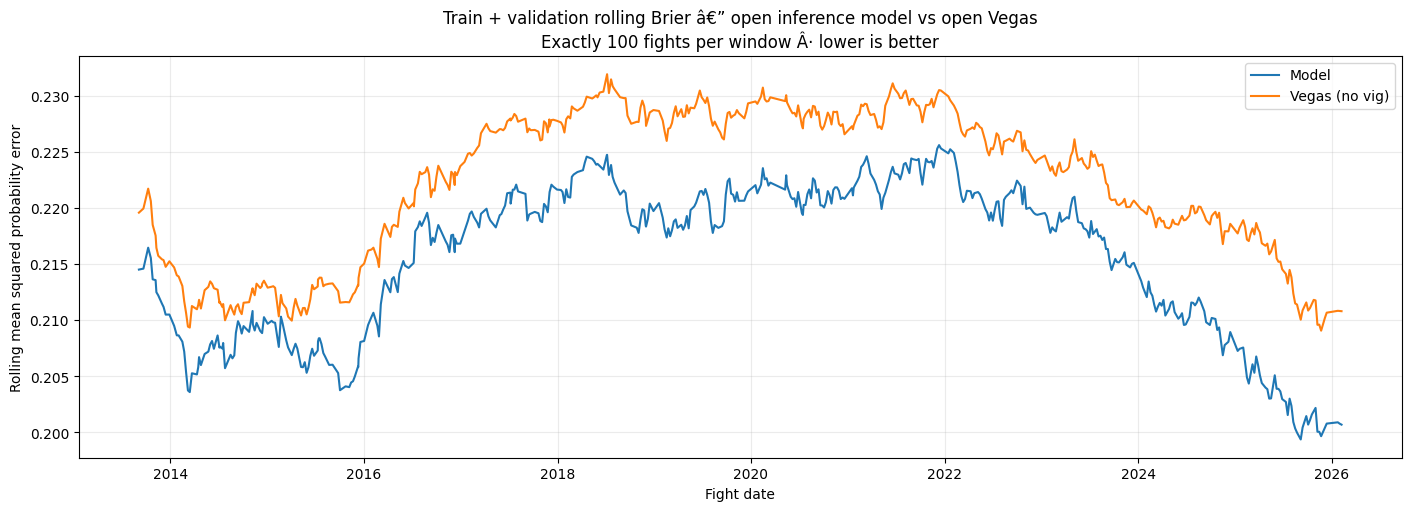

In [2]:
fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(scores.date, scores.rolling_model, label="Model", color="tab:blue")
ax.plot(scores.date, scores.rolling_vegas, label="Vegas (no vig)", color="tab:orange")
ax.set(title=f"Train + validation rolling Brier â€” {MODEL_TYPE} {PROBABILITY_MODEL} model vs {ODDS_TYPE} Vegas"
             f"\nExactly {WINDOW} fights per window Â· lower is better",
       xlabel="Fight date", ylabel="Rolling mean squared probability error")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.25)
ax.legend()
plt.show()


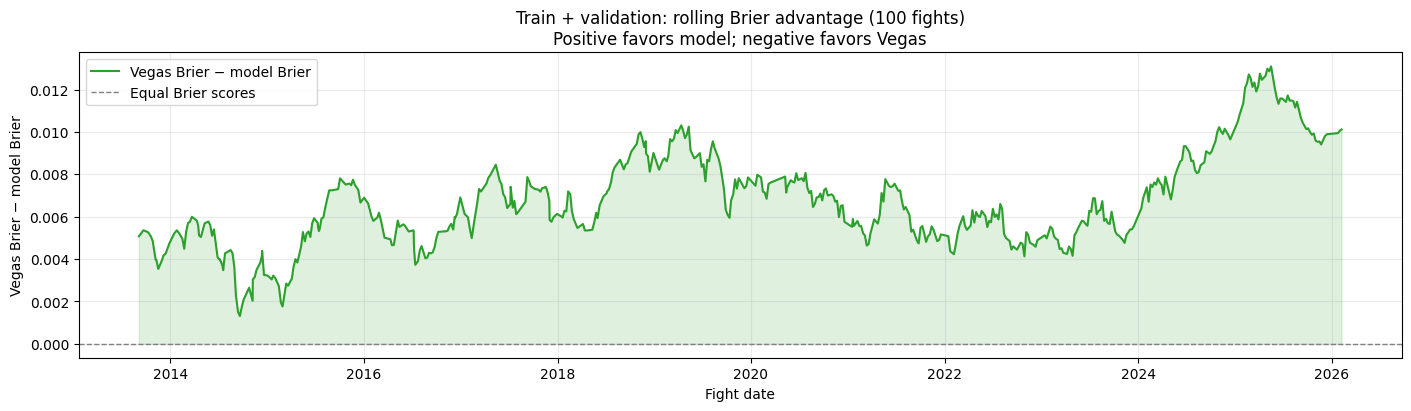

In [3]:
# Positive values mean the model has a lower (better) rolling Brier score.
scores["rolling_brier_advantage"] = scores.rolling_vegas - scores.rolling_model
fig, ax = plt.subplots(figsize=(14, 4), constrained_layout=True)
ax.plot(scores.date, scores.rolling_brier_advantage, color="tab:green",
        label="Vegas Brier − model Brier")
ax.axhline(0, color="gray", linestyle="--", linewidth=1, label="Equal Brier scores")
ax.fill_between(scores.date, 0, scores.rolling_brier_advantage,
                where=scores.rolling_brier_advantage.ge(0), color="tab:green", alpha=.15)
ax.fill_between(scores.date, 0, scores.rolling_brier_advantage,
                where=scores.rolling_brier_advantage.lt(0), color="tab:red", alpha=.15)
ax.set(title=f"Train + validation: rolling Brier advantage ({WINDOW} fights)"
             "\nPositive favors model; negative favors Vegas",
       xlabel="Fight date", ylabel="Vegas Brier − model Brier")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.25)
ax.legend()
plt.show()


## Vegas excess Brier over time

For each fight, let `p` be Vegas's no-vig red-win probability and `y` the outcome
(1 for a red win, 0 for a blue win). Actual Brier is `(p - y)**2`.
If `p` is the true win probability, expected Brier is
`p * (1 - p)**2 + (1 - p) * p**2 = p * (1 - p)`.

We calculate this expectation separately for every fight, then average over the
same 100-event window. We do **not** apply the formula to the average probability.
Excess Brier = actual Brier minus expected Brier. Above zero means outcomes scored
worse than the market's own probability-based baseline; below zero means better.
This is a descriptive diagnostic, not a standalone calibration test: positive and
negative errors can cancel, and at p=0.5 excess Brier is always zero.


Full-period actual: 0.2212; expected: 0.2263; excess: -0.0051


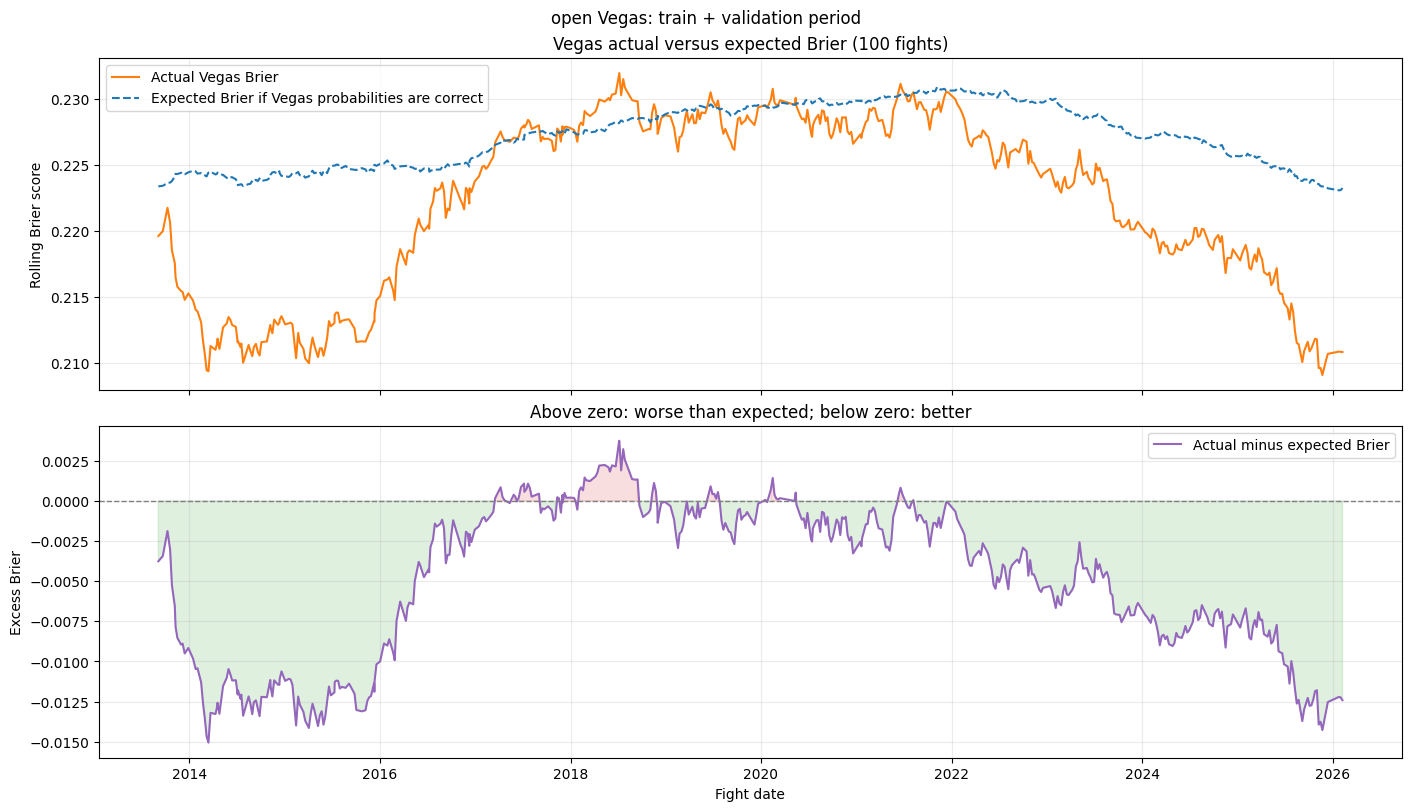

In [4]:
scores["vegas_excess_brier"] = scores.vegas_brier - scores.vegas_expected_brier
scores["rolling_vegas_expected"] = scores.vegas_expected_brier.rolling(WINDOW, min_periods=WINDOW).mean()
scores["rolling_vegas_excess"] = scores.vegas_excess_brier.rolling(WINDOW, min_periods=WINDOW).mean()

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
axes[0].plot(scores.date, scores.rolling_vegas, color="tab:orange", label="Actual Vegas Brier")
axes[0].plot(scores.date, scores.rolling_vegas_expected, color="tab:blue", linestyle="--",
             label="Expected Brier if Vegas probabilities are correct")
axes[0].set(ylabel="Rolling Brier score", title=f"Vegas actual versus expected Brier ({WINDOW} fights)")
axes[1].plot(scores.date, scores.rolling_vegas_excess, color="tab:purple", label="Actual minus expected Brier")
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].fill_between(scores.date, 0, scores.rolling_vegas_excess,
                     where=scores.rolling_vegas_excess.ge(0), color="tab:red", alpha=.15)
axes[1].fill_between(scores.date, 0, scores.rolling_vegas_excess,
                     where=scores.rolling_vegas_excess.lt(0), color="tab:green", alpha=.15)
axes[1].set(xlabel="Fight date", ylabel="Excess Brier", title="Above zero: worse than expected; below zero: better")
locator = mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend()
fig.suptitle(f"{ODDS_TYPE} Vegas: train + validation period")
print(f"Full-period actual: {scores.vegas_brier.mean():.4f}; "
      f"expected: {scores.vegas_expected_brier.mean():.4f}; "
      f"excess: {scores.vegas_excess_brier.mean():+.4f}")
plt.show()


## Autocorrelation, unit roots, and shuffled-event cycle test

The ACF and ADF use **unsmoothed event-average actual Vegas Brier**, with one
observation per event date. A lag means events apart, not calendar months.
The ACF of the 100-event rolling curve is also shown, but its overlap creates
mechanical dependence and it must not be interpreted as independent evidence.

ADF null: the event-level series has a unit root. Rejection is evidence against
that null under the chosen specification; non-rejection does not prove a random
walk, and neither outcome proves or disproves cycles. Both constant-only and
constant-plus-linear-trend specifications are reported; lag length uses AIC.
Brier is bounded, making an unrestricted random walk an imperfect literal model.

Permutation null: whole event blocks are exchangeable in chronological order.
We shuffle events **without replacement**, keeping every event, its outcome,
probability, and within-event order intact. Each shuffled sample gets the same
100-event rolling calculation as the observed data.

The primary statistic is the largest periodogram power of the linearly detrended
rolling curve across periods from WINDOW / 2 events to one-third of the available
rolling observations (at least three repetitions). The maximum is recomputed for
each shuffle, accounting for the search across frequencies in this range.
A secondary statistic is rolling peak-to-trough range. Monte Carlo p-values use
(1 + number of null statistics at least as large as observed) / (permutations + 1).

These are exploratory tests because the waves have already been inspected.
Rejection indicates temporal structure beyond random event ordering, which can
also arise from changing event mix, trends, or regimes; it does not establish a
stable forecastable cycle. Periods here are measured in events, not calendar time.


In [ ]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import adfuller
from scipy.signal import periodogram

# Unsmoothed actual scores; do not substitute expected or excess Brier.
event_brier = scores.groupby("date", sort=True).vegas_brier.mean()
rolling_actual = scores.rolling_vegas.dropna().to_numpy()
ACF_LAGS = min(50, len(event_brier) // 4)
fig, axes = plt.subplots(2, 1, figsize=(13, 8), constrained_layout=True)
plot_acf(event_brier.to_numpy(), lags=ACF_LAGS, zero=False, ax=axes[0], alpha=.05)
axes[0].set(title="Actual Vegas Brier: unsmoothed event-average autocorrelation",
            xlabel="Lag (events)", ylabel="Autocorrelation")
plot_acf(rolling_actual, lags=min(200, len(rolling_actual)//4), zero=False,
         ax=axes[1], alpha=None)
axes[1].set(title=f"Rolling {WINDOW}-event actual Brier ACF — overlap creates dependence",
            xlabel="Lag (events)", ylabel="Autocorrelation")
for ax in axes:
    ax.grid(alpha=.2)
plt.show()

adf_records = []
for specification, label in [("c", "Constant"), ("ct", "Constant + trend")]:
    statistic, pvalue, used_lags, nobs, critical, _ = adfuller(
        event_brier.to_numpy(), regression=specification, autolag="AIC")
    adf_records.append({"specification": label, "ADF statistic": statistic,
                        "p-value": pvalue, "lags": used_lags, "observations": nobs,
                        "5% critical": critical["5%"],
                        "unit-root null at 5%": "Reject" if pvalue < .05 else "Do not reject"})
adf_results = pd.DataFrame(adf_records)
print(adf_results.to_string(index=False))
print("ADF rejection is not a test of whether there are cycles or whether returns are forecastable.")


In [ ]:
N_PERMUTATIONS = 2000
RANDOM_SEED = 42
MIN_PERIOD_FIGHTS = max(10, WINDOW // 2)
MAX_PERIOD_FIGHTS = len(rolling_actual) / 3
if MAX_PERIOD_FIGHTS <= MIN_PERIOD_FIGHTS:
    raise ValueError("Insufficient history for the specified cycle-period range")

blocks = [group.vegas_brier.to_numpy() for _, group in scores.groupby("date", sort=True)]

def rolling_values(values, window):
    cumulative = np.r_[0., np.cumsum(values, dtype=float)]
    return (cumulative[window:] - cumulative[:-window]) / window

def cycle_statistic(values):
    frequency, power = periodogram(values, detrend="linear", scaling="spectrum")
    eligible = ((frequency >= 1 / MAX_PERIOD_FIGHTS) &
                (frequency <= 1 / MIN_PERIOD_FIGHTS))
    indices = np.flatnonzero(eligible)
    peak = indices[np.argmax(power[eligible])]
    return float(power[peak]), float(1 / frequency[peak]), frequency, power

observed_peak, observed_period, frequency, observed_power = cycle_statistic(rolling_actual)
observed_range = float(np.ptp(rolling_actual))
rng = np.random.default_rng(RANDOM_SEED)
null_peak = np.empty(N_PERMUTATIONS)
null_range = np.empty(N_PERMUTATIONS)
for iteration in range(N_PERMUTATIONS):
    shuffled = np.concatenate([blocks[j] for j in rng.permutation(len(blocks))])
    null_rolling = rolling_values(shuffled, WINDOW)
    null_peak[iteration] = cycle_statistic(null_rolling)[0]
    null_range[iteration] = np.ptp(null_rolling)

peak_pvalue = (1 + np.count_nonzero(null_peak >= observed_peak)) / (N_PERMUTATIONS + 1)
range_pvalue = (1 + np.count_nonzero(null_range >= observed_range)) / (N_PERMUTATIONS + 1)
permutation_results = pd.DataFrame({
    "statistic": ["Maximum detrended spectral power (primary)", "Rolling range (secondary)"],
    "observed": [observed_peak, observed_range],
    "null 95th percentile": [np.quantile(null_peak, .95), np.quantile(null_range, .95)],
    "permutation p-value": [peak_pvalue, range_pvalue],
})
print(permutation_results.to_string(index=False))
print(f"Observed strongest period in tested range: {observed_period:.1f} events")
print(f"{len(blocks)} whole events; {N_PERMUTATIONS} permutations; seed={RANDOM_SEED}")
print("Primary conclusion: " + ("Reject" if peak_pvalue < .05 else "Do not reject") +
      " random event ordering at 5%. This does not establish a stable cycle.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for ax, null, observed, title, pvalue in [
    (axes[0], null_peak, observed_peak, "Maximum cycle power", peak_pvalue),
    (axes[1], null_range, observed_range, "Rolling peak-to-trough range", range_pvalue),
]:
    ax.hist(null, bins=40, alpha=.75, label="Shuffled whole events")
    ax.axvline(observed, color="tab:red", linewidth=2, label="Observed chronology")
    ax.set(title=f"{title}: permutation p={pvalue:.4f}", xlabel=title, ylabel="Permutation count")
    ax.legend()
plt.show()


## ARIMA: forecasting actual Vegas Brier on the held-out test events

Target: **unsmoothed mean actual Vegas Brier per event**, not the overlapping
100-event curve. Each event receives equal weight in evaluation. Dates label
observations; the model's time step is one event, not a fixed number of days.

Fit on the combined train + validation period. Select p and q from 0, 1, 2 by
training AICc, comparing a constant against a constant plus linear event-index
trend. Use d=0, consistent with the earlier ADF results: this allows stationary
fluctuations around a constant or deterministic trend. The test set does not
select the specification. Nonconverged fits are excluded.

Two separate evaluations are shown:
- **Fixed-origin:** forecast the entire test period before seeing any test outcomes.
- **Next-event:** forecast each event before observing its outcome, then update
  the model state with that result without refitting its coefficients.

Baselines: training mean, last-20-event mean, and last event. Next-event baselines
also update using completed events only. Forecast intervals are 95% model-based
intervals, assuming the selected ARIMA model; model-selection uncertainty is omitted.
Raw forecasts are not clipped to [0, 1]. This test period was already inspected in
previous analysis, so results are a retrospective holdout evaluation, not a fresh
untouched confirmation. Forecasting Vegas Brier does not establish betting edge.


## Before-event forecast of the event's rolling Brier

One forecast is issued before each event, targeting the **100-event rolling Brier
at the end of that event**. This averages this event's score and the previous 99 event scores. It is not the Brier average of just that event.

Both ARIMA training observations and plotted actual values are sampled once per
completed event. ARIMA's time step is now **one event**, not one fight. Orders are
selected by training-only AICc. Before each test event, forecast one event ahead;
after its results arrive, update the model state without refitting coefficients.

The x-axis is the target event date. The actual and forecast lines have exactly
one point per event on identical dates. The actual line is retrospective; it is
never used to forecast its own event. Baselines use only earlier completed events.
Both the historical curves and forecast targets now use event-level rolling averages. This is a retrospective test on previously inspected
data, not an untouched prospective assessment.

Expanded search: p and q each range from 0 through 5. For d=0, compare a
constant and a constant plus linear trend; for d=1, compare no-drift models.
This gives 108 specifications. Higher p/q are lag orders, not polynomial-trend
degrees. Selection uses training AICc among converged fits only; BIC is also
reported. The full ranking is available as `rolling_candidate_table`.


In [ ]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test_events = rolling_test.groupby('date',sort=True).vegas_brier.mean()
raw_test = raw_test_events.to_numpy()
# One training observation per completed event: the final 100-event average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_event_values = pd.Series(combined_rolling.iloc[len(raw_train):].to_numpy(),index=raw_test_events.index)
rolling_test_actual = rolling_test.date.map(rolling_test_event_values).to_numpy()

# Editable search limits: p = AR lags, q = moving-average error lags.
MAX_AR_ORDER = 5
MAX_MA_ORDER = 5
rolling_specs = [((ar, 0, ma), trend)
                 for ar in range(MAX_AR_ORDER + 1)
                 for ma in range(MAX_MA_ORDER + 1)
                 for trend in ('c', 'ct')]
# Retain integrated alternatives as well; no drift in these candidates.
rolling_specs += [((ar, 1, ma), 'n')
                  for ar in range(MAX_AR_ORDER + 1)
                  for ma in range(MAX_MA_ORDER + 1)]
print(f'Testing {len(rolling_specs)} ARIMA specifications on training data only.')
rolling_fits = {}
rolling_candidate_records = []
for order, trend in rolling_specs:
    try:
        with warnings.catch_warnings(record=True):
            candidate = ARIMA(rolling_train_values, order=order, trend=trend).fit(
                method_kwargs={"maxiter": 300})
        converged = bool(candidate.mle_retvals.get('converged', True))
        rolling_candidate_records.append(dict(order=str(order), trend=trend,
                                              AICc=candidate.aicc, BIC=candidate.bic, converged=converged))
        if converged and np.isfinite(candidate.aicc):
            rolling_fits[(order, trend)] = candidate
    except (ValueError, np.linalg.LinAlgError) as exc:
        rolling_candidate_records.append(dict(order=str(order), trend=trend,
                                              AICc=np.nan, BIC=np.nan, converged=False))
if not rolling_fits:
    raise RuntimeError("No rolling-series ARIMA candidates converged")
rolling_best_key = min(rolling_fits, key=lambda key: rolling_fits[key].aicc)
rolling_fit = rolling_fits[rolling_best_key]
rolling_candidate_table = pd.DataFrame(rolling_candidate_records).sort_values('AICc')
print("Rolling-series training selection:")
print(rolling_candidate_table.head(20).to_string(index=False))
print(f'{len(rolling_fits)} of {len(rolling_specs)} candidates converged with finite AICc.')
print('Full results: rolling_candidate_table; nonconverged candidates cannot be selected.')
print('Best converged candidates by (d, trend):')
print(rolling_candidate_table.loc[rolling_candidate_table.converged].assign(
    d=lambda frame: frame.order.map(lambda order: int(order.split(",")[1]))
).groupby(['d', 'trend'], sort=False).head(1).to_string(index=False))
print(f"Selected ARIMA{rolling_best_key[0]}, trend={rolling_best_key[1]}")

# Target for each event is the final rolling value after every fight on that card.
rolling_test['rolling_actual'] = rolling_test_actual
test_event_rolling = rolling_test.groupby('date', sort=True).rolling_actual.last()
state = rolling_fit
history = list(rolling_train_values)
records = []
for event_date, actual in test_event_rolling.items():
    # Forecast before this event; no outcomes from this card are available here.
    forecast = state.get_forecast(steps=1)
    interval = np.asarray(forecast.conf_int(alpha=.05))[0]
    records.append(dict(event_date=event_date, actual=actual,
                        ARIMA=float(np.asarray(forecast.predicted_mean)[0]),
                        Persistence=history[-1], recent20=np.mean(history[-20:]),
                        lower=interval[0], upper=interval[1],
                        information_through=(train_event_rolling.index[-1] if not records else records[-1]['event_date'])))
    # Update only after this entire event has completed.
    state = state.extend([actual])
    history.append(actual)
event_rolling_forecasts = pd.DataFrame(records).set_index('event_date')
metric_records = []
for method in ('ARIMA', 'Persistence', 'recent20'):
    error = event_rolling_forecasts[method] - event_rolling_forecasts.actual
    metric_records.append(dict(method=method, events=len(error),
                               RMSE=np.sqrt(np.mean(error**2)), MAE=np.mean(np.abs(error))))
event_rolling_accuracy = pd.DataFrame(metric_records)
print(f"\nOne forecast before each of {len(test_event_rolling)} test events; target = post-event {WINDOW}-event rolling Brier")
print(event_rolling_accuracy.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)
ax.plot(event_rolling_forecasts.index, event_rolling_forecasts.actual, 'o-',
        color='black', label='Actual rolling Brier after event')
ax.plot(event_rolling_forecasts.index, event_rolling_forecasts.ARIMA, 'o-',
        color='tab:blue', label='ARIMA forecast made before event')
ax.plot(event_rolling_forecasts.index, event_rolling_forecasts.Persistence, 'x--',
        color='tab:orange', label='Persistence: previous event rolling Brier')
ax.fill_between(event_rolling_forecasts.index, event_rolling_forecasts.lower,
                event_rolling_forecasts.upper, color='tab:blue', alpha=.12,
                label='ARIMA 95% forecast interval')
ax.set(title=f'Before-event forecast of after-event {WINDOW}-event rolling Vegas Brier',
       xlabel='Target event date', ylabel=f'Rolling Brier (last {WINDOW} fights)')
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(fontsize=9); ax.grid(alpha=.2)
plt.show()


## ARIMA lag search: p=15–45, d=0 or 1, q=1–10

620 combinations evaluated on the chronological one-event-ahead
training forecast origins. Select by RMSE on the **original rolling-Brier level**,
not on differences. For d=1, predict the next change and add it to the latest
observed level. Regression target dates are aligned across d=0 and d=1.

Uses two-stage Hannan–Rissanen-style ARMA estimation with a 60-lag pilot and a
common 70-observation hold-back, not maximum-likelihood ARIMA. Each model has
an intercept (a drift term in the differenced equation when d=1). Stable AR and
invertible MA coefficients are required at every origin and final refit; rejected
models and reasons remain in `arma_lag_search`. Refit coefficients at each training
origin, select without test data, then refit on all train+validation. Test forecasts
keep coefficients fixed and update observations/innovations only after each event.
The plot compares the best MA order at each AR lag for each differencing order.


In [ ]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test_events = rolling_test.groupby('date',sort=True).vegas_brier.mean()
raw_test = raw_test_events.to_numpy()
# One training observation per completed event: the final 100-event average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_event_values = pd.Series(combined_rolling.iloc[len(raw_train):].to_numpy(),index=raw_test_events.index)
rolling_test_actual = rolling_test.date.map(rolling_test_event_values).to_numpy()


# Two-stage (Hannan-Rissanen style) conditional ARMA estimation.
from scipy.signal import lfilter
from threadpoolctl import threadpool_limits
MIN_AR_LAG, MAX_AR_LAG = 15, 45
MIN_MA_ORDER, MAX_MA_ORDER = 1, 10
DIFFERENCING_ORDERS = (0, 1)
PILOT_AR_LAG = 60
INITIAL_TRAIN_FRACTION = .70
ar_y = train_event_rolling.to_numpy()
initial_count = max(PILOT_AR_LAG + 40, int(len(ar_y) * INITIAL_TRAIN_FRACTION))
HOLD_BACK = PILOT_AR_LAG + MAX_MA_ORDER
if initial_count >= len(ar_y):
    raise ValueError('Not enough events for forward selection')

def prepare_arma_history(history):
    y = np.asarray(history, dtype=float)
    pilot_indices = np.arange(PILOT_AR_LAG, len(y))
    pilot_X = np.column_stack([np.ones(len(pilot_indices))] +
                             [y[pilot_indices-j] for j in range(1, PILOT_AR_LAG+1)])
    pilot_coef = np.linalg.lstsq(pilot_X, y[pilot_indices], rcond=None)[0]
    residual = np.zeros(len(y))
    residual[pilot_indices] = y[pilot_indices] - pilot_X @ pilot_coef
    indices = np.arange(HOLD_BACK, len(y))
    ar_columns = np.column_stack([np.ones(len(indices))] +
                                [y[indices-j] for j in range(1, MAX_AR_LAG+1)])
    ma_columns = np.column_stack([residual[indices-j] for j in range(1, MAX_MA_ORDER+1)])
    return y, indices, ar_columns, ma_columns

def fit_arma_prepared(prepared, p, q):
    y, indices, ar_columns, ma_columns = prepared
    X = np.column_stack([ar_columns[:, :p+1], ma_columns[:, :q]])
    coefficients, _, rank, _ = np.linalg.lstsq(X, y[indices], rcond=None)
    if rank < X.shape[1] or not np.isfinite(coefficients).all():
        raise ValueError('Rank-deficient ARMA fit')
    phi, theta = coefficients[1:p+1], coefficients[p+1:]
    # Enforce stable AR and invertible MA before using recursive innovations.
    if np.max(np.abs(np.roots(np.r_[1., -phi]))) >= 1:
        raise ValueError('Unstable AR coefficients')
    if q and np.max(np.abs(np.roots(np.r_[1., theta]))) >= 1:
        raise ValueError('Noninvertible MA coefficients')
    return coefficients

def forecast_arma(coefficients, history, p, q):
    y = np.asarray(history, dtype=float)
    phi, theta = coefficients[1:p+1], coefficients[p+1:]
    conditional = y.copy() - coefficients[0]
    for j, coefficient in enumerate(phi, 1):
        conditional[j:] -= coefficient*y[:-j]
    conditional[:p] = 0.
    innovations = lfilter([1.], np.r_[1., theta], conditional)
    prediction = coefficients[0] + phi @ y[-p:][::-1]
    if q:
        prediction += theta @ innovations[-q:][::-1]
    return float(prediction)

def transformed_history(history, d):
    # Align regression target dates across d=0 and d=1 candidates.
    values = np.asarray(history, dtype=float)
    return values[1:] if d == 0 else np.diff(values)

def forecast_level(coefficients, history, p, d, q):
    prediction = forecast_arma(coefficients, transformed_history(history, d), p, q)
    return prediction if d == 0 else float(history[-1] + prediction)

specs = [(p,d,q) for p in range(MIN_AR_LAG, MAX_AR_LAG+1)
         for d in DIFFERENCING_ORDERS for q in range(MIN_MA_ORDER, MAX_MA_ORDER+1)]
cv_predictions = {spec: [] for spec in specs}
failures = {}
with threadpool_limits(limits=1):
    for origin in range(initial_count, len(ar_y)):
        prepared = {d: prepare_arma_history(transformed_history(ar_y[:origin], d))
                    for d in DIFFERENCING_ORDERS}
        for spec in specs:
            if spec in failures:
                continue
            p, d, q = spec
            try:
                coefficients = fit_arma_prepared(prepared[d], p, q)
                predicted = forecast_level(coefficients, ar_y[:origin], p, d, q)
                if not np.isfinite(predicted):
                    raise ValueError('Nonfinite forecast')
                cv_predictions[spec].append(predicted)
            except ValueError as exc:
                failures[spec] = str(exc)
    final_prepared = {d: prepare_arma_history(transformed_history(ar_y, d))
                      for d in DIFFERENCING_ORDERS}
    full_fits = {}
    for spec in specs:
        if spec not in failures:
            p, d, q = spec
            try:
                full_fits[spec] = fit_arma_prepared(final_prepared[d], p, q)
            except ValueError as exc:
                failures[spec] = 'Full-training fit: ' + str(exc)

actual_cv = ar_y[initial_count:]
search_records = []
for p,d,q in specs:
    spec = (p,d,q)
    predictions = np.asarray(cv_predictions[spec])
    valid = spec not in failures and len(predictions)==len(actual_cv)
    error = predictions-actual_cv if valid else np.array([np.nan])
    search_records.append(dict(p=p,d=d,q=q, forecasts=len(predictions), eligible=valid,
        RMSE=np.sqrt(np.mean(error**2)), MAE=np.mean(np.abs(error)),
        reason=failures.get(spec,'')))
arma_lag_search = pd.DataFrame(search_records).sort_values(['RMSE','p','d','q']).reset_index(drop=True)
eligible = arma_lag_search.loc[arma_lag_search.eligible]
if eligible.empty:
    raise RuntimeError('No stable/invertible candidate completed all forward origins')
best_p, best_d, best_q = (int(eligible.iloc[0][key]) for key in ('p','d','q'))
best_coefficients = full_fits[(best_p,best_d,best_q)]
print(f'{len(specs)} candidates; {len(actual_cv)} forward events per eligible candidate; {len(eligible)} eligible.')
print(arma_lag_search.head(30).to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Full 620-row results: arma_lag_search. Best eligible model per differencing order:')
print(eligible.groupby('d',sort=True).head(1).to_string(index=False))
print(f'Selected ARIMA({best_p}, {best_d}, {best_q}) by training forward RMSE; two-stage estimation.')

rolling_test['rolling_actual'] = rolling_test_actual
test_event_rolling = rolling_test.groupby('date', sort=True).rolling_actual.last()
history = list(ar_y)
records=[]
for date, actual in test_event_rolling.items():
    records.append(dict(event_date=date, actual=actual,
        ARMA=forecast_level(best_coefficients,history,best_p,best_d,best_q),
        Persistence=history[-1], recent20=np.mean(history[-20:]),
        information_through=train_event_rolling.index[-1] if not records else records[-1]['event_date']))
    history.append(actual)
arma_event_forecasts=pd.DataFrame(records).set_index('event_date')
metrics=[]
for method in ('ARMA','Persistence','recent20'):
    error=arma_event_forecasts[method]-arma_event_forecasts.actual
    metrics.append(dict(method=method,events=len(error),RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
arma_test_accuracy=pd.DataFrame(metrics)
print('\nTest accuracy (coefficients fixed; lag values and innovations updated after each event):')
print(arma_test_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))

fig,axes=plt.subplots(2,1,figsize=(14,10),constrained_layout=True)
# Plot the best eligible MA order at each AR lag for each differencing order.
for d, group in eligible.groupby('d'):
    best_by_p = group.sort_values(['RMSE','q']).groupby('p',sort=True).head(1).sort_values('p')
    axes[0].plot(best_by_p.p,best_by_p.RMSE,'o-',label=f'd={d}: best MA order at each p')
axes[0].scatter([best_p],[eligible.iloc[0].RMSE],color='black',s=100,marker='*',label='Selected')
axes[0].set(xlabel='AR lag count (events)',ylabel='Forward RMSE on Brier level',
            title='AR 15–45, MA 1–10, differencing 0 or 1')
axes[1].plot(arma_event_forecasts.index,arma_event_forecasts.actual,'o-',color='black',label='Actual after-event rolling Brier')
axes[1].plot(arma_event_forecasts.index,arma_event_forecasts.ARMA,'o-',label=f'ARIMA({best_p},{best_d},{best_q}) before-event forecast')
axes[1].plot(arma_event_forecasts.index,arma_event_forecasts.Persistence,'x--',label='Persistence')
axes[1].set(xlabel='Target event date',ylabel='100-event rolling Brier',title='Test-period next-event forecasts')
locator=mdates.AutoDateLocator()
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
for ax in axes:
    ax.legend();ax.grid(alpha=.2)
plt.show()


## ARIMAX: expected Vegas Brier as a pre-event predictor

Predictor: **100-event rolling expected Vegas Brier at the event end**, computed
from each fight's no-vig probability `p*(1-p)`. It matches the target's window and
is known once the card and the selected odds snapshot are available. No current
or future outcomes enter the predictor. Each event's forecast receives that event's
expected score before actual results update the model.

Search AR lags 0–20 for ARIMAX, with d=1 and q=1 fixed. Each candidate fits
on the first 70% of training events and forecasts the remaining 30% one event at
a time, updating state without coefficient refitting. Select by forward RMSE,
breaking exact ties toward fewer lags. Exclude failed or nonconverged fits.
Then compare ARIMA and ARIMAX at that selected order, refitting both on all
train+validation for test evaluation. Both use maximum-likelihood estimation.
The ARIMA comparison uses the ARIMAX-selected order; it is not independently tuned.
The test set does not decide whether the feature or order should be used.

This retrospective comparison keeps the notebook's eligible settled-fight cohort.
Its event-end windows exclude eventual voids as elsewhere in the notebook, so
live deployment must explicitly handle cancellations/voids without knowing them
in advance. Opening prices are pre-event inputs here; other markets must be
available at the intended forecast time. Expected Brier is computed per fight
before averaging, not from the average probability.


In [ ]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test_events = rolling_test.groupby('date',sort=True).vegas_brier.mean()
raw_test = raw_test_events.to_numpy()
# One training observation per completed event: the final 100-event average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_event_values = pd.Series(combined_rolling.iloc[len(raw_train):].to_numpy(),index=raw_test_events.index)
rolling_test_actual = rolling_test.date.map(rolling_test_event_values).to_numpy()



from threadpoolctl import threadpool_limits
ARIMAX_ORDER = (0, 1, 1)  # p selected below; d=1 and q=1 remain fixed
ARIMAX_LAGS = range(21)

train_x = pd.Series(scores.vegas_expected_brier.to_numpy(),index=pd.DatetimeIndex(scores.date)).rolling(WINDOW,min_periods=WINDOW).mean().loc[train_event_rolling.index]
test_r=rolling_test[f'dec_{ODDS_TYPE}_red'].to_numpy(float)
test_b=rolling_test[f'dec_{ODDS_TYPE}_blue'].to_numpy(float)
test_probability=(1/test_r)/(1/test_r+1/test_b)
test_expected_events=pd.Series(test_probability*(1-test_probability),index=pd.DatetimeIndex(rolling_test.date)).groupby(level=0).mean()
all_expected=pd.concat([pd.Series(scores.vegas_expected_brier.to_numpy(),index=pd.DatetimeIndex(scores.date)),test_expected_events])
rolling_test['rolling_actual']=rolling_test_actual
test_y=rolling_test.groupby('date',sort=True).rolling_actual.last()
test_x=all_expected.rolling(WINDOW,min_periods=WINDOW).mean().loc[test_y.index]
y_train = train_event_rolling.to_numpy()
x_train = train_x.to_numpy()
if not np.isfinite(np.r_[x_train,test_x.to_numpy()]).all():
    raise ValueError('Expected Brier predictor must be finite')

fit_records=[]
def fit_comparison(y,x,use_exog,label,order=None):
    order = ARIMAX_ORDER if order is None else order
    # Scaling helps optimization of small-valued Brier data.
    y_center,y_scale=float(np.mean(y)),float(np.std(y))
    x_center,x_scale=float(np.mean(x)),float(np.std(x))
    if y_scale<=0 or x_scale<=0:
        raise ValueError('Constant training series')
    with warnings.catch_warnings(record=True) as captured:
        result=ARIMA((y-y_center)/y_scale,
            exog=((x-x_center)/x_scale)[:,None] if use_exog else None,
            order=order,trend='n' if order[1] else 'c').fit(method_kwargs={'maxiter':500})
    converged=bool(result.mle_retvals.get('converged',True))
    fit_records.append(dict(stage=label,order=str(order),model='ARIMAX' if use_exog else 'ARIMA',
                            converged=converged,warnings='; '.join(str(w.message) for w in captured)))
    if not converged:
        raise RuntimeError(f'{label} fit did not converge; do not interpret this comparison')
    return result,y_center,y_scale,x_center,x_scale

def forecast_events(fitted,y,x,use_exog):
    state,y_center,y_scale,x_center,x_scale=fitted
    predictions=[]
    for actual,predictor in zip(y,x):
        exog=np.array([[(predictor-x_center)/x_scale]]) if use_exog else None
        forecast=state.forecast(steps=1,exog=exog)
        predictions.append(float(np.asarray(forecast)[0])*y_scale+y_center)
        state=state.extend([(actual-y_center)/y_scale],exog=exog)
    return np.asarray(predictions)

cut=int(.70*len(y_train))
# Same training forecast origins for all lag orders; test outcomes are not consulted.
arimax_search_records=[]
with threadpool_limits(limits=1):
    for lag in ARIMAX_LAGS:
        try:
            fitted=fit_comparison(y_train[:cut],x_train[:cut],True,f'Lag search p={lag}',order=(lag,1,1))
            predicted=forecast_events(fitted,y_train[cut:],x_train[cut:],True)
            error=predicted-y_train[cut:]
            if not np.isfinite(error).all():
                raise ValueError('Nonfinite forecast')
            arimax_search_records.append(dict(p=lag,d=1,q=1,RMSE=np.sqrt(np.mean(error**2)),
                MAE=np.mean(np.abs(error)),eligible=True,reason=''))
        except (RuntimeError,ValueError,np.linalg.LinAlgError) as exc:
            arimax_search_records.append(dict(p=lag,d=1,q=1,RMSE=np.nan,MAE=np.nan,
                eligible=False,reason=str(exc)))
arimax_lag_search=pd.DataFrame(arimax_search_records).sort_values(['RMSE','p']).reset_index(drop=True)
eligible_search=arimax_lag_search.loc[arimax_lag_search.eligible]
if eligible_search.empty:
    raise RuntimeError('No ARIMAX lag candidates completed forward evaluation')
ARIMAX_ORDER=(int(eligible_search.iloc[0].p),1,1)
print('Expected-Brier ARIMAX lag search: training-period next-event forecast errors')
print(arimax_lag_search.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print(f'Selected {ARIMAX_ORDER} using training forward RMSE only.')
fig,ax=plt.subplots(figsize=(12,4),constrained_layout=True)
lag_plot=arimax_lag_search.sort_values('p')
ax.plot(lag_plot.p,lag_plot.RMSE,'o-')
ax.axvline(ARIMAX_ORDER[0],color='tab:red',linestyle='--',label=f'Selected p={ARIMAX_ORDER[0]}')
ax.set(title='ARIMAX with expected Brier: AR lags 0–20 (d=1, q=1)',
       xlabel='AR lag count (events)',ylabel='Training forward RMSE')
ax.legend();ax.grid(alpha=.2)
plt.show()
comparison_metrics=[]
arimax_test_forecasts=pd.DataFrame({'actual':test_y,'expected_brier':test_x})
with threadpool_limits(limits=1):
    for use_exog in (False,True):
        name='ARIMAX' if use_exog else 'ARIMA'
        cvfit=fit_comparison(y_train[:cut],x_train[:cut],use_exog,'Training forward check')
        cvpred=forecast_events(cvfit,y_train[cut:],x_train[cut:],use_exog)
        finalfit=fit_comparison(y_train,x_train,use_exog,'Full training refit')
        testpred=forecast_events(finalfit,test_y.to_numpy(),test_x.to_numpy(),use_exog)
        arimax_test_forecasts[name]=testpred
        for stage,predicted,actual in [('Training forward',cvpred,y_train[cut:]),('Test',testpred,test_y.to_numpy())]:
            error=predicted-actual
            comparison_metrics.append(dict(stage=stage,model=name,events=len(error),
                                            RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
# Matching persistence forecasts, using only the last completed event.
for stage,actual,last in [('Training forward',y_train[cut:],y_train[cut-1]),('Test',test_y.to_numpy(),y_train[-1])]:
    predicted=np.r_[last,actual[:-1]]
    error=predicted-actual
    comparison_metrics.append(dict(stage=stage,model='Persistence',events=len(error),
                                    RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
    if stage=='Test':arimax_test_forecasts['Persistence']=predicted
arimax_accuracy=pd.DataFrame(comparison_metrics).sort_values(['stage','RMSE'])
arimax_fit_diagnostics=pd.DataFrame(fit_records)
print(f'Order: {ARIMAX_ORDER}; expected Brier predictor uses no-vig {ODDS_TYPE} probabilities.')
print(arimax_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print(arimax_fit_diagnostics[['stage','model','converged']].to_string(index=False))
fig,ax=plt.subplots(figsize=(14,6),constrained_layout=True)
for name,style in [('actual','ko-'),('ARIMA','--'),('ARIMAX','o-'),('Persistence',':')]:
    ax.plot(arimax_test_forecasts.index,arimax_test_forecasts[name],style,label=name)
ax.set(title='Before-event forecasts: with versus without expected Vegas Brier',
       xlabel='Target event date',ylabel=f'After-event {WINDOW}-event rolling Brier')
locator=mdates.AutoDateLocator();ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.2);ax.legend()
plt.show()


## Stochastic-cycle forecast: irregular waves instead of fixed harmonics

A structural state-space model separates a changing level/trend, an optional
stochastic cycle, and observation noise. Random cycle shocks allow phase and
amplitude to change, so realized peaks need not be equally spaced. The model
still estimates a characteristic frequency; it does not explicitly estimate a
separate free period at every instant. Damping permits oscillations to fade.

Use a **daily calendar grid**, with missing observations on non-event days (no
interpolation). The Kalman filter handles these gaps. Observations remain the
post-event 100-event rolling actual Vegas Brier. A forecast issued the day before
each event uses only completed events strictly before that issue date.

Search local-level versus local-linear-trend specifications, with no cycle,
an undamped stochastic cycle, or a damped stochastic cycle. Cycle period bounds
are 30–1,000 calendar days. Select by one-day-before-event RMSE over the final
30% of training events, then refit using all train+validation. Coefficients remain
fixed within each evaluation; filtered states update as earlier events become
available. Report a cycle-free baseline and persistence alongside the best cycle
model, even if the cycle-free model wins. Nonconverged fits are excluded.

This replaces the fixed-harmonic experiment. Test data is previously inspected,
so this remains retrospective evidence, not independent confirmation.


In [ ]:
import warnings
from statsmodels.tsa.arima.model import ARIMA

# Independent setup: uses the same ordering and eligible rows as the original curve.
rolling_test_path = prediction_path.with_name(f"test_with_{ODDS_TYPE}.csv")
rolling_test = pd.read_csv(rolling_test_path)
rolling_test["date"] = pd.to_datetime(rolling_test.date, errors="raise")
test_order = ["date"] + (["bout_position"] if "bout_position" in rolling_test else [])
rolling_test = rolling_test.sort_values(test_order + ["fighter_red", "fighter_blue"], kind="stable")
r = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_red"], errors="coerce")
b = pd.to_numeric(rolling_test[f"dec_{ODDS_TYPE}_blue"], errors="coerce")
valid_test = (rolling_test.winner.isin([0, 1]) & rolling_test.date.notna()
              & pd.to_numeric(rolling_test.proba_red, errors="coerce").between(0, 1)
              & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
p_test = (1/r) / (1/r + 1/b)
rolling_test = rolling_test.loc[valid_test].copy()
rolling_test["vegas_brier"] = (p_test.loc[valid_test] - rolling_test.winner)**2
rolling_test = rolling_test.reset_index(drop=True)
if rolling_test.empty or rolling_test.date.min() <= scores.date.max():
    raise ValueError("Test must strictly follow the training period")
raw_train = scores.vegas_brier.to_numpy()
raw_test_events = rolling_test.groupby('date',sort=True).vegas_brier.mean()
raw_test = raw_test_events.to_numpy()
# One training observation per completed event: the final 100-event average.
train_event_rolling = scores.groupby('date', sort=True).rolling_vegas.last().dropna()
rolling_train_values = train_event_rolling.to_numpy()
combined_rolling = pd.Series(np.r_[raw_train, raw_test]).rolling(WINDOW, min_periods=WINDOW).mean()
rolling_test_event_values = pd.Series(combined_rolling.iloc[len(raw_train):].to_numpy(),index=raw_test_events.index)
rolling_test_actual = rolling_test.date.map(rolling_test_event_values).to_numpy()





from statsmodels.tsa.statespace.structural import UnobservedComponents
from threadpoolctl import threadpool_limits

rolling_test['rolling_actual']=rolling_test_actual
test_event_rolling=rolling_test.groupby('date',sort=True).rolling_actual.last()
PERIOD_BOUNDS=(30.,1000.)
cv_start=int(.70*len(train_event_rolling))
initial_events=train_event_rolling.iloc[:cv_start]
cv_events=train_event_rolling.iloc[cv_start:]

def fit_structural(events,spec):
    spec = {**spec, **{key: bool(spec[key]) for key in ('trend','cycle','damped')}}
    daily=events.asfreq('D') # Non-event days remain NaN.
    center=float(events.mean());scale=float(events.std())
    if scale<=0:raise ValueError('Constant series')
    model=UnobservedComponents((daily-center)/scale,
        level=True,trend=spec['trend'],stochastic_level=True,
        stochastic_trend=spec['trend'],irregular=True,
        cycle=spec['cycle'],stochastic_cycle=spec['cycle'],
        damped_cycle=spec['damped'],cycle_period_bounds=PERIOD_BOUNDS)
    with warnings.catch_warnings(record=True):
        fit=model.fit(disp=False,maxiter=400)
        if not fit.mle_retvals.get('converged',True):
            fit=model.fit(start_params=fit.params,method='powell',disp=False,maxiter=600)
    if not fit.mle_retvals.get('converged',True):raise ValueError('Fit did not converge')
    frequency=fit.params.get('frequency.cycle',np.nan)
    period=2*np.pi/frequency if np.isfinite(frequency) and frequency>0 else np.nan
    return fit,center,scale,float(period)

def forecast_before_events(fitted,prior_events,targets):
    state,center,scale,_=fitted
    available_series=pd.concat([prior_events,targets]).sort_index()
    last_state_date=prior_events.index[-1]
    rows=[]
    for target_date,actual in targets.items():
        issue_date=target_date-pd.Timedelta(days=1)
        cutoff=issue_date-pd.Timedelta(days=1)
        if last_state_date>cutoff:raise ValueError('State contains information after forecast cutoff')
        if last_state_date<cutoff:
            dates=pd.date_range(last_state_date+pd.Timedelta(days=1),cutoff,freq='D')
            new_values=available_series.reindex(dates)
            state=state.extend((new_values-center)/scale)
            last_state_date=cutoff
        steps=(target_date-last_state_date).days
        forecast=state.get_forecast(steps=steps)
        predicted=float(forecast.predicted_mean.iloc[-1])*scale+center
        interval=np.asarray(forecast.conf_int())[-1]*scale+center
        known=available_series.loc[available_series.index<=cutoff]
        rows.append(dict(event_date=target_date,issue_date=issue_date,
                         information_through=known.index[-1],actual=actual,
                         prediction=predicted,lower=interval[0],upper=interval[1],
                         Persistence=known.iloc[-1]))
    return pd.DataFrame(rows).set_index('event_date')

specifications=[]
for trend in (False,True):
    for cycle,damped in [(False,False),(True,False),(True,True)]:
        name=('Local trend' if trend else 'Local level') + (' + damped stochastic cycle' if damped else ' + stochastic cycle' if cycle else '')
        specifications.append(dict(name=name,trend=trend,cycle=cycle,damped=damped))
search=[]
with threadpool_limits(limits=1):
    for spec in specifications:
        try:
            fitted=fit_structural(initial_events,spec)
            predicted=forecast_before_events(fitted,initial_events,cv_events)
            error=predicted.prediction-predicted.actual
            if not np.isfinite(error).all():raise ValueError('Nonfinite forecasts')
            search.append(dict(**spec,RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error)),
                               period_days=fitted[3],eligible=True,reason=''))
        except (ValueError,np.linalg.LinAlgError) as exc:
            search.append(dict(**spec,RMSE=np.nan,MAE=np.nan,period_days=np.nan,eligible=False,reason=str(exc)))
stochastic_cycle_search=pd.DataFrame(search).sort_values('RMSE').reset_index(drop=True)
valid=stochastic_cycle_search.loc[stochastic_cycle_search.eligible]
if valid.empty or not valid.cycle.any():raise RuntimeError('No eligible stochastic-cycle fit')
best_cycle=valid.loc[valid.cycle].iloc[0]
best_baseline=valid.loc[~valid.cycle].iloc[0]
print('Training forward selection:')
print(stochastic_cycle_search.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Overall training winner:',valid.iloc[0]['name'])

cycle_test_forecasts={};test_metrics=[]
with threadpool_limits(limits=1):
    for row in (best_cycle,best_baseline):
        spec={key:row[key] for key in ('name','trend','cycle','damped')}
        fitted=fit_structural(train_event_rolling,spec)
        predictions=forecast_before_events(fitted,train_event_rolling,test_event_rolling)
        cycle_test_forecasts[spec['name']]=predictions
        error=predictions.prediction-predictions.actual
        test_metrics.append(dict(model=spec['name'],events=len(error),RMSE=np.sqrt(np.mean(error**2)),
                                 MAE=np.mean(np.abs(error)),fitted_period_days=fitted[3]))
reference=next(iter(cycle_test_forecasts.values()))
error=reference.Persistence-reference.actual
test_metrics.append(dict(model='Persistence',events=len(error),RMSE=np.sqrt(np.mean(error**2)),
                         MAE=np.mean(np.abs(error)),fitted_period_days=np.nan))
stochastic_cycle_test_accuracy=pd.DataFrame(test_metrics).sort_values('RMSE')
print('\nTest: issued the day before each event')
print(stochastic_cycle_test_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))

fig,ax=plt.subplots(figsize=(14,6),constrained_layout=True)
ax.plot(reference.index,reference.actual,'ko-',label='Actual post-event rolling Brier')
for name,predictions in cycle_test_forecasts.items():
    ax.plot(predictions.index,predictions.prediction,'o-',label=name)
ax.plot(reference.index,reference.Persistence,'--',label='Persistence')
ax.set(title='Stochastic-cycle state-space forecast, issued one day before event',
       xlabel='Target event date',ylabel='Post-event 100-event rolling Vegas Brier')
locator=mdates.AutoDateLocator();ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.legend(fontsize=8);ax.grid(alpha=.2)
plt.show()


## Detrended rolling actual Vegas Brier

Train + validation, using the existing 100-event rolling average. Fit a straight
line against elapsed calendar days over this displayed period, then subtract it.
Only the residual is plotted. This is retrospective linear detrending, not a
forecast or a causal feature: the fitted line uses the whole displayed period.


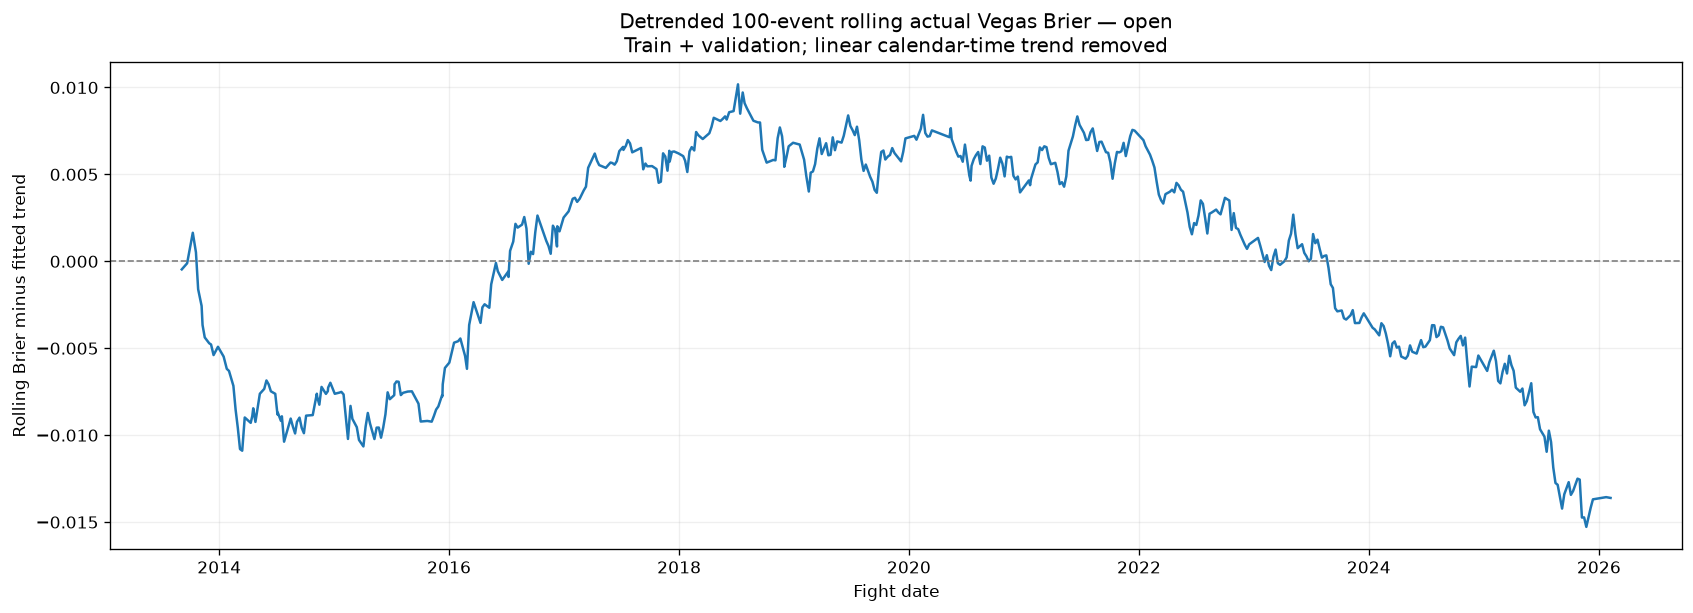

In [5]:
detrended_brier = scores.loc[scores.rolling_vegas.notna(), ["date", "rolling_vegas"]].copy()
elapsed_days = (detrended_brier.date - detrended_brier.date.min()).dt.total_seconds().to_numpy() / 86400
trend_design = np.column_stack([np.ones(len(elapsed_days)), elapsed_days])
trend_coefficients = np.linalg.lstsq(trend_design, detrended_brier.rolling_vegas.to_numpy(), rcond=None)[0]
detrended_brier["linear_trend"] = trend_design @ trend_coefficients
detrended_brier["residual"] = detrended_brier.rolling_vegas - detrended_brier.linear_trend

fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
ax.plot(detrended_brier.date, detrended_brier.residual, color="tab:blue")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set(title=f"Detrended {WINDOW}-event rolling actual Vegas Brier — {ODDS_TYPE}"
             "\nTrain + validation; linear calendar-time trend removed",
       xlabel="Fight date", ylabel="Rolling Brier minus fitted trend")
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(alpha=.2)
plt.show()


## Cycle tests: train + validation rolling Brier advantage

Advantage = **Vegas Brier minus model Brier**; positive favors the model. Use the
same 100-event rolling average and eligible train+validation fights as above.
These model probabilities were fitted on train+validation, so findings concern
in-sample advantage, not demonstrated future betting performance.

Two exploratory tests, with periods from 50 events (half the window) to one-third
of the rolling-series length:
1. Maximum spectral power after linear detrending.
2. Maximum repeated autocorrelation alignment: average normalized ACF at lag T
   and lag 2T, searching all integer T in that period range. This measures recurring
   shape alignment rather than absolute amplitude. Negative ACF is not rewarded.

Shuffle whole event blocks without replacement 2,000 times, keeping paired model
and Vegas errors and within-event fight order together. Recompute rolling averages,
detrending, and the full period search for every shuffle. The null is random event
ordering (exchangeable event blocks), not every conceivable noncyclical process.
Report Monte Carlo p-values with +1 correction and Holm adjustment across the two
tests. Overlap-induced dependence is present in both observed and shuffled curves.

Rejecting this null shows temporal structure inconsistent with random ordering;
trend changes or regimes can also cause rejection. It does not by itself establish
stable future cycles. Failing to reject is not proof that no cycle exists. Periods
are in events, not calendar days, and these tests follow visual exploration.


In [ ]:
from scipy.signal import detrend, periodogram
from scipy.fft import rfft, irfft, next_fast_len

ADVANTAGE_PERMUTATIONS = 2000
ADVANTAGE_SEED = 42
advantage_events = scores[["date", "vegas_brier", "model_brier"]].copy()
advantage_events["advantage"] = advantage_events.vegas_brier - advantage_events.model_brier

def advantage_rolling(values):
    cumulative = np.r_[0., np.cumsum(values, dtype=float)]
    return (cumulative[WINDOW:] - cumulative[:-WINDOW]) / WINDOW

observed_advantage = advantage_rolling(advantage_events.advantage.to_numpy())
advantage_dates = advantage_events.date.iloc[WINDOW-1:]
MIN_CYCLE = max(10, WINDOW // 2)
MAX_CYCLE = len(observed_advantage) // 3
if MAX_CYCLE <= MIN_CYCLE:
    raise ValueError("Insufficient data for at least three repetitions in the tested range")
cycle_lags = np.arange(MIN_CYCLE, MAX_CYCLE+1)

def advantage_cycle_metrics(values):
    residual = detrend(values, type='linear')
    frequency, power = periodogram(residual, detrend=False, scaling='spectrum')
    mask = (frequency >= 1/MAX_CYCLE) & (frequency <= 1/MIN_CYCLE)
    spectral_indices = np.flatnonzero(mask)
    peak = spectral_indices[np.argmax(power[mask])]
    nfft = next_fast_len(2*len(residual)-1)
    transform = rfft(residual, nfft)
    covariance = irfft(transform * transform.conj(), nfft)[:len(residual)]
    if covariance[0] <= 0:
        raise ValueError('Constant advantage series')
    acf = covariance / covariance[0]
    alignment = (acf[cycle_lags] + acf[2*cycle_lags]) / 2
    best = int(np.argmax(alignment))
    return dict(power=float(power[peak]), spectral_period=float(1/frequency[peak]),
                alignment=float(alignment[best]), acf_period=int(cycle_lags[best]),
                acf=acf, residual=residual, frequency=frequency, spectrum=power)

observed_cycle = advantage_cycle_metrics(observed_advantage)
blocks = [group.advantage.to_numpy() for _,group in advantage_events.groupby('date',sort=True)]
rng = np.random.default_rng(ADVANTAGE_SEED)
null_statistics = np.empty((ADVANTAGE_PERMUTATIONS,2))
for iteration in range(ADVANTAGE_PERMUTATIONS):
    shuffled = np.concatenate([blocks[j] for j in rng.permutation(len(blocks))])
    result = advantage_cycle_metrics(advantage_rolling(shuffled))
    null_statistics[iteration] = result['power'], result['alignment']
observed_stats = np.array([observed_cycle['power'],observed_cycle['alignment']])
raw_p = (1 + (null_statistics >= observed_stats).sum(axis=0))/(ADVANTAGE_PERMUTATIONS+1)
order = np.argsort(raw_p)
adjusted_p = np.empty(2)
adjusted_p[order] = np.minimum(1, np.maximum.accumulate(raw_p[order] * np.array([2,1])))
advantage_cycle_results = pd.DataFrame({
    'test':['Maximum detrended spectral power','Repeated ACF alignment at T and 2T'],
    'observed':observed_stats,
    'candidate_period_events':[observed_cycle['spectral_period'],observed_cycle['acf_period']],
    'permutation_p':raw_p, 'Holm_adjusted_p':adjusted_p,
    'reject_at_5pct':adjusted_p<.05,
})
print(f'Train+validation: {len(advantage_events)} events, {len(blocks)} events; window={WINDOW}.')
print(f'Tested periods: {MIN_CYCLE}–{MAX_CYCLE} events; {ADVANTAGE_PERMUTATIONS} whole-event shuffles.')
print(advantage_cycle_results.to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Probabilities are in-sample trainval fits. These are exploratory temporal-structure tests.')

fig,axes = plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
axes[0,0].plot(advantage_dates,observed_cycle['residual'])
axes[0,0].axhline(0,color='gray',linestyle='--')
axes[0,0].set(title='Detrended rolling Brier advantage',xlabel='Fight date',ylabel='Vegas Brier − model Brier (detrended)')
locator=mdates.AutoDateLocator();axes[0,0].xaxis.set_major_locator(locator)
axes[0,0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[0,1].plot(np.arange(2*MAX_CYCLE+1),observed_cycle['acf'][:2*MAX_CYCLE+1])
for lag in (observed_cycle['acf_period'],2*observed_cycle['acf_period']):
    axes[0,1].axvline(lag,color='tab:red',linestyle='--',alpha=.7)
axes[0,1].axhline(0,color='gray',linewidth=1)
axes[0,1].set(title='Normalized ACF (dashed: selected T and 2T)',xlabel='Lag in events',ylabel='Autocorrelation')
for j,ax in enumerate(axes[1]):
    ax.hist(null_statistics[:,j],bins=40,alpha=.75,label='Shuffled events')
    ax.axvline(observed_stats[j],color='tab:red',linewidth=2,label='Observed')
    ax.set(title=f'{advantage_cycle_results.test.iloc[j]}\nHolm-adjusted p={adjusted_p[j]:.4f}',
           xlabel='Test statistic',ylabel='Permutation count')
    ax.legend()
for ax in axes.flat:ax.grid(alpha=.2)
plt.show()


## Adaptive oscillator for detrended rolling Brier advantage

Target: event-end 100-event rolling **Vegas Brier minus model Brier**. Positive
advantage favors the model. Remove a linear calendar-time trend fitted on training
history only. Unlike fixed harmonics, this oscillator has a time-varying frequency:
a noisy two-dimensional rotation represents the wave and its phase, while log
frequency follows a random walk. An extended Kalman filter learns amplitude,
phase, and frequency from successive observations. Candidate periods are bounded
to 30–1,000 days; seed periods are initialization choices, not fixed cycle lengths.

Tune process/observation noise and initial period using next-event forecast RMSE
on the last 30% of training events. Its detrending line uses only the initial 70%.
Then refit the trend on all train+validation and filter through that history before
forecasting test events. Each forecast is recorded before its event observation
updates the state. No test outcomes select settings or fit the trend.

**Filtered tracking** uses the current event observation and is not a forecast.
It is shown separately from **pre-event predictions**. The estimated period is a
model interpretation, not proof of a physical cycle; frequency changes can be
weakly identified. All trainval model probabilities are in-sample; test predictions
are from the separate test export. This remains retrospective, previously explored
data. The event-end target retains the notebook's settled-fight cohort.


In [ ]:
from itertools import product

# Build the same advantage series, sampled once at the end of each event.
osc_train_fights=scores[['date','model_brier','vegas_brier']].copy()
osc_train_fights['raw_advantage']=osc_train_fights.vegas_brier-osc_train_fights.model_brier
osc_train_fights['rolling_advantage']=osc_train_fights.raw_advantage.rolling(WINDOW,min_periods=WINDOW).mean()
osc_train=osc_train_fights.groupby('date',sort=True).rolling_advantage.last().dropna()
osc_test_path=prediction_path.with_name(f'test_with_{ODDS_TYPE}.csv')
osc_test_fights=pd.read_csv(osc_test_path)
osc_test_fights['date']=pd.to_datetime(osc_test_fights.date)
osc_sort=['date']+(['bout_position'] if 'bout_position' in osc_test_fights else [])+['fighter_red','fighter_blue']
osc_test_fights=osc_test_fights.sort_values(osc_sort,kind='stable').reset_index(drop=True)
r=pd.to_numeric(osc_test_fights[f'dec_{ODDS_TYPE}_red'],errors='coerce')
b=pd.to_numeric(osc_test_fights[f'dec_{ODDS_TYPE}_blue'],errors='coerce')
m=pd.to_numeric(osc_test_fights.proba_red,errors='coerce')
valid_osc=(osc_test_fights.winner.isin([0,1]) & osc_test_fights.date.notna() & m.between(0,1)
           & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1))
v=(1/r)/(1/r+1/b)
osc_test_fights['raw_advantage']=(v-osc_test_fights.winner)**2-(m-osc_test_fights.winner)**2
osc_test_fights=osc_test_fights.loc[valid_osc].groupby('date',sort=True).raw_advantage.mean().reset_index()
combined=pd.Series(np.r_[osc_train_fights.raw_advantage.to_numpy(),osc_test_fights.raw_advantage.to_numpy()])
osc_test_fights['rolling_advantage']=combined.rolling(WINDOW,min_periods=WINDOW).mean().iloc[len(osc_train_fights):].to_numpy()
osc_test=osc_test_fights.groupby('date',sort=True).rolling_advantage.last()
if osc_test.index.min()<=osc_train.index.max():raise ValueError('Overlapping train/test events')
OSC_ORIGIN=osc_train.index[0]

def oscillator_trend_fit(series):
    t=(series.index-OSC_ORIGIN).days.to_numpy()/365.25
    design=np.column_stack([np.ones(len(t)),t])
    coefficient=np.linalg.lstsq(design,series.to_numpy(),rcond=None)[0]
    residual=series.to_numpy()-design@coefficient
    scale=float(np.std(residual))
    if scale<=0:raise ValueError('Constant detrended series')
    return coefficient,scale

def oscillator_trend(dates,coefficient):
    t=(pd.DatetimeIndex(dates)-OSC_ORIGIN).days.to_numpy()/365.25
    return coefficient[0]+coefficient[1]*t

def oscillator_path(series,coefficient,scale,seed_period,amplitude_noise,frequency_noise,observation_noise):
    # State = [wave coordinate, quadrature coordinate, log angular frequency].
    # Rotation uses actual elapsed days between observations.
    residual=(series.to_numpy()-oscillator_trend(series.index,coefficient))/scale
    state=np.array([residual[0],0.,np.log(2*np.pi/seed_period)])
    covariance=np.diag([observation_noise**2,1.,.25])
    low,high=np.log(2*np.pi/1000),np.log(2*np.pi/30)
    rows=[]
    previous=series.index[0]
    H=np.array([1.,0.,0.])
    for i,(date,actual) in enumerate(zip(series.index,residual)):
        dt=float((date-previous).days)
        if i:
            omega=np.exp(state[2]);theta=omega*dt
            c,s=np.cos(theta),np.sin(theta)
            x,z,log_frequency=state
            predicted=np.array([c*x-s*z,s*x+c*z,log_frequency])
            jacobian=np.array([[c,-s,(-s*x-c*z)*theta],
                               [s,c,(c*x-s*z)*theta],[0.,0.,1.]])
            process=np.diag([amplitude_noise**2*dt,amplitude_noise**2*dt,frequency_noise**2*dt])
            covariance=jacobian@covariance@jacobian.T+process
            state=predicted
        pre=float(state[0])
        # Current outcome is used only after the prediction above is recorded.
        variance=float(covariance[0,0]+observation_noise**2)
        gain=covariance[:,0]/variance
        state=state+gain*(actual-state[0])
        state[2]=np.clip(state[2],low,high)
        adjustment=np.eye(3)-np.outer(gain,H)
        covariance=adjustment@covariance@adjustment.T+np.outer(gain,gain)*observation_noise**2
        covariance=(covariance+covariance.T)/2
        rows.append(dict(date=date,actual=actual*scale,prediction=pre*scale,
                         filtered=state[0]*scale,period_days=2*np.pi/np.exp(state[2]),
                         amplitude=np.hypot(state[0],state[1])*scale))
        previous=date
    return pd.DataFrame(rows).set_index('date')

osc_cut=int(.70*len(osc_train))
cv_trend,cv_scale=oscillator_trend_fit(osc_train.iloc[:osc_cut])
osc_candidates=[]
for seed,amp,freq,noise in product([60.,180.,540.],[.005,.02],[.005,.03],[.05,.2]):
    params=dict(seed_period=seed,amplitude_noise=amp,frequency_noise=freq,observation_noise=noise)
    path=oscillator_path(osc_train,cv_trend,cv_scale,**params).iloc[osc_cut:]
    error=path.prediction-path.actual
    osc_candidates.append(dict(**params,RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
oscillator_search=pd.DataFrame(osc_candidates).sort_values('RMSE').reset_index(drop=True)
osc_best={key:float(oscillator_search.iloc[0][key]) for key in
          ('seed_period','amplitude_noise','frequency_noise','observation_noise')}
osc_coefficient,osc_scale=oscillator_trend_fit(osc_train)
osc_all=pd.concat([osc_train,osc_test])
oscillator_results=oscillator_path(osc_all,osc_coefficient,osc_scale,**osc_best)
oscillator_results['trend']=oscillator_trend(oscillator_results.index,osc_coefficient)
oscillator_results['advantage_forecast']=oscillator_results.prediction+oscillator_results.trend
# First observation only initializes the filter; never evaluate it as a forecast.
osc_eval=oscillator_results.loc[osc_test.index].copy()
osc_eval['Persistence']=oscillator_results.actual.shift(1).loc[osc_test.index]
osc_eval['Raw advantage persistence']=osc_all.shift(1).loc[osc_test.index]-osc_eval.trend
metrics=[]
for method in ('prediction','Persistence','Raw advantage persistence'):
    error=osc_eval[method]-osc_eval.actual
    metrics.append(dict(model=method,events=len(error),RMSE=np.sqrt(np.mean(error**2)),MAE=np.mean(np.abs(error))))
oscillator_test_accuracy=pd.DataFrame(metrics).sort_values('RMSE')
print('Training forward candidates (top 8):')
print(oscillator_search.head(8).to_string(index=False,float_format=lambda x:f'{x:.6f}'))
print('Selected adaptive-oscillator settings:',osc_best)
print('\nTest forecasts on detrended advantage (prediction = oscillator):')
print(oscillator_test_accuracy.to_string(index=False,float_format=lambda x:f'{x:.6f}'))

fig,axes=plt.subplots(3,1,figsize=(15,13),constrained_layout=True)
training=oscillator_results.loc[osc_train.index]
axes[0].plot(training.index,training.actual,color='black',alpha=.65,label='Detrended rolling advantage')
axes[0].plot(training.index,training.filtered,color='tab:blue',label='Filtered oscillator tracking (uses current observation)')
axes[0].set(title='Train + validation: adaptive tracking of the oscillation',ylabel='Detrended advantage')
axes[1].plot(oscillator_results.index,oscillator_results.period_days,color='tab:purple')
axes[1].axvline(osc_train.index[-1],color='gray',linestyle='--',label='Train/test boundary')
axes[1].set(title='Estimated cycle duration changes over time',ylabel='Estimated period (days)',ylim=(0,1050))
axes[2].plot(osc_eval.index,osc_eval.actual,'ko-',label='Actual detrended advantage')
axes[2].plot(osc_eval.index,osc_eval.prediction,'o-',label='Oscillator forecast BEFORE event')
axes[2].plot(osc_eval.index,osc_eval.Persistence,'--',label='Persistence')
axes[2].set(title='Test: pre-event forecasts, without current-event updates',ylabel='Detrended advantage',xlabel='Event date')
for ax in axes:
    locator=mdates.AutoDateLocator();ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.grid(alpha=.2)
    handles,_=ax.get_legend_handles_labels()
    if handles:ax.legend(fontsize=8)
plt.show()


## Does rolling Brier advantage correlate with strategy returns?

Use only the opening inference model **fitted on training data alone**, evaluated
on its saved validation backtest. Each fight's probability is verified against
`report_predictions/train/open/inference/val_with_open.csv`. This cell is pinned
to that source independently of FIT_MODE or model settings elsewhere in the notebook.
The trainval-fitted test run is excluded.

Return = 100 × (moneyline P/L + parlay P/L) / event-start bankroll. Event-level
fields are counted once, not once per fight. No-bet events remain in the sample;
post-ruin events are excluded. This is event bankroll return, not ROI on stake.

For all settled fights and placed moneylines, first average advantage within each
event, then average over 100 events. A choice event with no eligible bet is missing,
not replaced by a different event. This older validation-only advantage cell has
only 72 events and no training strategy history, so a complete 100-event choice
window is unavailable. Its outputs were cleared. The next analysis uses training
Vegas scores for warmup and computes the requested event-window return correlations.


In [ ]:
from scipy.stats import pearsonr, spearmanr

RETURN_WINDOW = 100
RETURN_BOOTSTRAPS = 2000
RETURN_BLOCK_EVENTS = 5
RETURN_SEED = 42
backtest_root = settings.data_dir / 'backtest_results' / 'model_comparisons' / 'inference_market_models'
# Pin this analysis to the opening inference model fitted on TRAIN ONLY.
RETURN_ODDS_TYPE = 'open'
return_paths = {'Validation': backtest_root / 'train_val_open_with_open_inference_no_decay_moneylines.csv'}
return_prediction_path = (settings.data_dir / 'model_comparisons' / 'lr_open_close'
                          / 'report_predictions' / 'train' / 'open' / 'inference' / 'val_with_open.csv')
return_reference = pd.read_csv(return_prediction_path)
if not return_reference.probability_model.eq('inference').all():
    raise ValueError('Expected inference probabilities')

def strategy_advantage_events(path):
    frame = pd.read_csv(path)
    keys = ['date','fighter_red','fighter_blue']
    matched = frame.merge(return_reference[keys+['proba_red']],on=keys,how='outer',
                          validate='one_to_one',indicator=True)
    if not matched['_merge'].eq('both').all():
        raise ValueError('Backtest and train-only validation predictions do not match')
    saved_red = matched.choice_proba.where(matched.pred_winner.eq(1),1-matched.choice_proba)
    np.testing.assert_allclose(saved_red,matched.proba_red,rtol=1e-10,atol=1e-12)

    frame['date'] = pd.to_datetime(frame.date).dt.normalize()
    frame = frame.sort_values('date', kind='stable').reset_index(drop=True)
    event_columns = ['bankroll_postevent', 'event_payout_money_line', 'parlay_net']
    if (frame.groupby('date')[event_columns].nunique(dropna=False)>1).any().any():
        raise ValueError('Expected identical event-level balances/P&L within each date')
    events = frame.groupby('date',sort=True)[event_columns].first()
    events['profit'] = events.event_payout_money_line + events.parlay_net
    events['starting_bankroll'] = events.bankroll_postevent - events.profit
    np.testing.assert_allclose(events.starting_bankroll.iloc[1:],events.bankroll_postevent.iloc[:-1],rtol=1e-7,atol=1e-6)
    events['return_pct'] = 100*events.profit/events.starting_bankroll.where(events.starting_bankroll>0)
    if 'choice_proba' in frame:
        model = frame.choice_proba.where(frame.pred_winner.eq(1),1-frame.choice_proba)
    else:
        model = frame.proba_red
    red,blue = f'dec_{RETURN_ODDS_TYPE}_red',f'dec_{RETURN_ODDS_TYPE}_blue'
    if red not in frame: red,blue='real_odds_red','real_odds_blue'
    prices = frame[[red,blue]].to_numpy(float)
    vegas = (1/frame[red])/(1/frame[red]+1/frame[blue])
    valid = (frame.winner.isin([0,1]) & model.between(0,1) & np.isfinite(prices).all(axis=1)
             & (prices>1).all(axis=1))
    frame['advantage'] = (vegas-frame.winner)**2 - (model-frame.winner)**2
    placed = frame.choice_fstar.gt(0) & frame.date.map(events.starting_bankroll).gt(0)
    for cohort,mask in [('all',valid),('choices',valid & placed)]:
        fights=frame.loc[mask,['date','advantage']].copy()
        event_advantage=fights.groupby('date',sort=True).advantage.mean().reindex(events.index)
        events[f'{cohort}_same']=event_advantage.rolling(RETURN_WINDOW,min_periods=RETURN_WINDOW).mean()
    return events

def block_correlation_interval(x,y,rng):
    n=len(x);length=min(RETURN_BLOCK_EVENTS,n)
    starts=rng.integers(0,n-length+1,size=(RETURN_BOOTSTRAPS,int(np.ceil(n/length))))
    indices=(starts[:,:,None]+np.arange(length)).reshape(RETURN_BOOTSTRAPS,-1)[:,:n]
    a=x[indices];b=y[indices]
    a=a-a.mean(axis=1,keepdims=True);b=b-b.mean(axis=1,keepdims=True)
    denominator=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    correlations=np.divide((a*b).sum(axis=1),denominator,out=np.full(RETURN_BOOTSTRAPS,np.nan),where=denominator>0)
    finite=correlations[np.isfinite(correlations)]
    return np.quantile(finite,[.025,.975]) if len(finite) else [np.nan,np.nan]

return_event_data={};correlation_records=[]
rng=np.random.default_rng(RETURN_SEED)
for period,path in return_paths.items():
    events=strategy_advantage_events(path)
    return_event_data[period]=events
    for cohort in ('all','choices'):
        for timing in ('same',):
            sample=events[[f'{cohort}_{timing}','return_pct']].dropna()
            x=sample.iloc[:,0].to_numpy();y=sample.return_pct.to_numpy()
            pearson=spearman=lo=hi=np.nan
            if len(sample)>=4 and np.std(x)>0 and np.std(y)>0:
                pearson=float(pearsonr(x,y).statistic);spearman=float(spearmanr(x,y).statistic)
                lo,hi=block_correlation_interval(x,y,rng)
            correlation_records.append(dict(period=period,cohort=cohort,timing=timing,events=len(sample),
                Pearson=pearson,Spearman=spearman,CI_low=lo,CI_high=hi))
return_correlation_results=pd.DataFrame(correlation_records)
print('Source: opening inference model fitted on train only; validation observations. Probabilities verified against saved prediction export.')
print('Same-event analysis only. Advantage and returns both include current-event outcomes. Returns include singles and parlays.')
for period, event_data in return_event_data.items():
    for cohort in ('all','choices'):
        eligible_events = event_data[[f'{cohort}_same','return_pct']].dropna()
        print(f'{period} {cohort}: {len(eligible_events)} events; first complete window {eligible_events.index.min()}')
print(return_correlation_results.to_string(index=False,float_format=lambda x:f'{x:.4f}'))

fig,axes=plt.subplots(1,2,figsize=(14,5),squeeze=False,constrained_layout=True)
for row,(period,events) in enumerate(return_event_data.items()):
    for col,cohort in enumerate(('all','choices')):
        ax=axes[row,col]
        sample=events[[f'{cohort}_same','return_pct']].dropna()
        ax.scatter(sample.iloc[:,0],sample.return_pct,alpha=.7)
        if len(sample)>1 and sample.iloc[:,0].std()>0:
            slope,intercept=np.polyfit(sample.iloc[:,0],sample.return_pct,1)
            grid=np.linspace(sample.iloc[:,0].min(),sample.iloc[:,0].max(),100)
            ax.plot(grid,intercept+slope*grid,color='tab:red',label='Descriptive linear fit')
            ax.legend(fontsize=8)
        ax.axhline(0,color='gray',linestyle='--');ax.axvline(0,color='gray',linestyle=':')
        ax.set(title=f'{period}: {cohort}, same-event advantage (n={len(sample)})',
               xlabel='Same-event rolling Brier advantage',ylabel='Current event bankroll return (%)')
        ax.grid(alpha=.2)
plt.show()


## Vegas Brier versus same-event returns: event windows

Uses the train-only opening inference model's validation strategy. Compare actual
and expected Vegas Brier averaged over the latest **1, 25, 50, 75, 100 events**,
including the current event, against its bankroll return. No shifted lag.
Earlier training events from the same model seed the windows, so all 72 validation
events can be evaluated even for the 100-event window. No training returns enter
the correlations. Event weights are equal regardless of card size. Actual Brier
and return share current outcomes: these are descriptive same-event associations.
Bootstrap intervals use 5-event blocks and are approximate, especially with
strong overlap at long windows; they are not definitive significance tests.


All windows count EVENTS. No lag shift: rolling score through event t versus return at event t.
Earlier training events seed the windows; all correlation returns are validation-only.
             measure  window_events  pairs  Pearson  Spearman  CI_low  CI_high
  actual_vegas_brier              1     72   0.3218    0.3429  0.1075   0.4525
  actual_vegas_brier             25     72   0.2777    0.2822  0.1237   0.4167
  actual_vegas_brier             50     72   0.2577    0.2667  0.0501   0.3782
  actual_vegas_brier             75     72   0.2677    0.2643  0.0797   0.3903
  actual_vegas_brier            100     72   0.2525    0.2582  0.0393   0.4043
expected_vegas_brier              1     72   0.0628    0.0432 -0.1378   0.1991
expected_vegas_brier             25     72   0.2021    0.1625  0.0130   0.3240
expected_vegas_brier             50     72   0.2355    0.2023  0.0285   0.3571
expected_vegas_brier             75     72   0.2001    0.1751 -0.0056   0.3363
expected_vegas_brier       

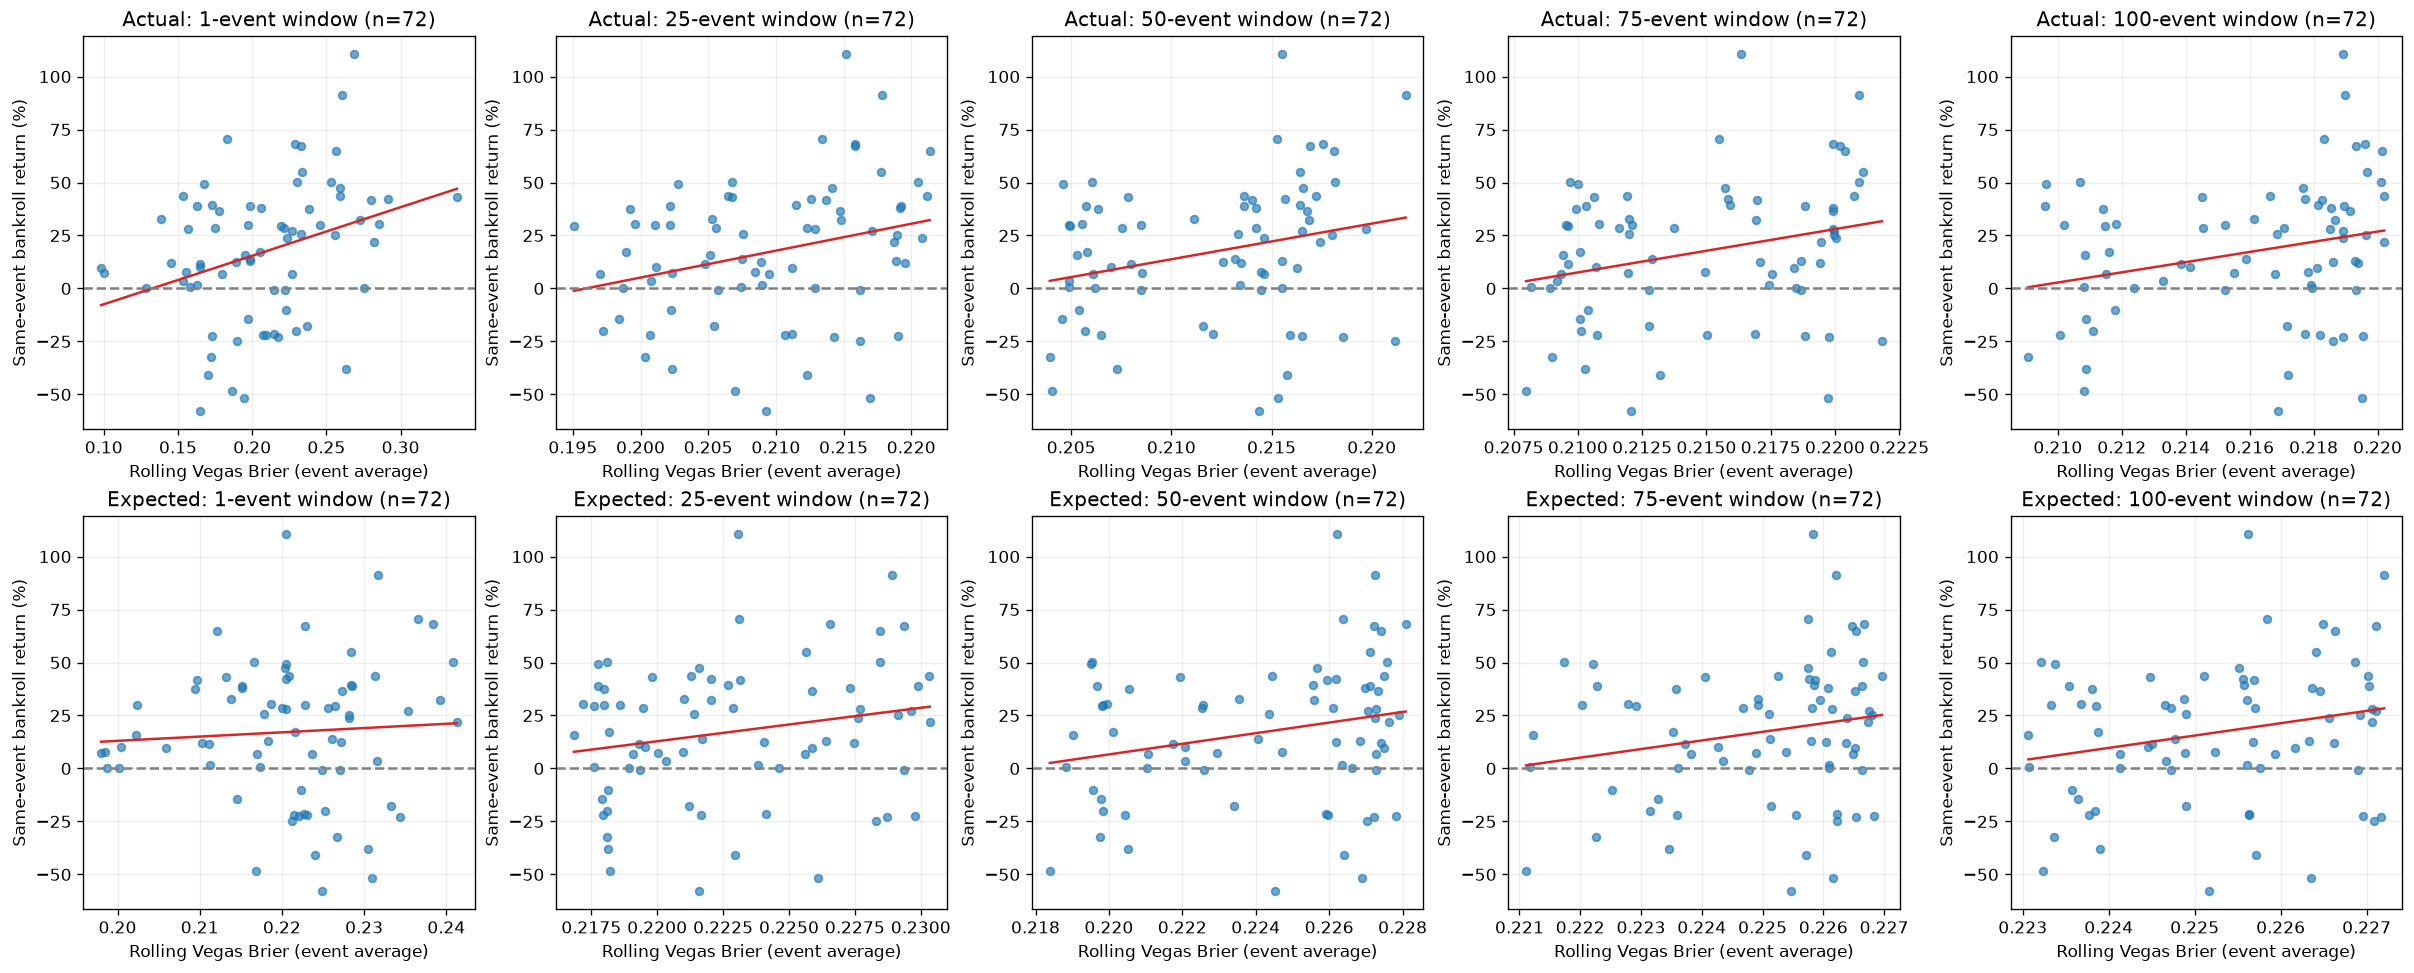

In [6]:
from scipy.stats import pearsonr, spearmanr

EVENT_WINDOWS = [1, 25, 50, 75, 100]
EVENT_BOOTSTRAPS = 2000
EVENT_BLOCK_LENGTH = 5
EVENT_CORRELATION_SEED = 42
source_root = settings.data_dir / 'backtest_results' / 'model_comparisons' / 'inference_market_models'
event_source = source_root / 'train_val_open_with_open_inference_no_decay_moneylines.csv'
reference_source = (settings.data_dir / 'model_comparisons' / 'lr_open_close' / 'report_predictions'
                    / 'train' / 'open' / 'inference' / 'val_with_open.csv')
fights = pd.read_csv(event_source)
reference = pd.read_csv(reference_source)
keys = ['date','fighter_red','fighter_blue']
verified = fights.merge(reference[keys+['proba_red','probability_model']],on=keys,
                        how='outer',validate='one_to_one',indicator=True)
if not verified['_merge'].eq('both').all() or not verified.probability_model.eq('inference').all():
    raise ValueError('Backtest does not match train-only opening inference validation export')
saved_probability = verified.choice_proba.where(verified.pred_winner.eq(1),1-verified.choice_proba)
np.testing.assert_allclose(saved_probability,verified.proba_red,rtol=1e-10,atol=1e-12)
fights['date'] = pd.to_datetime(fights.date).dt.normalize()
fights = fights.sort_values('date',kind='stable')
balance_columns = ['bankroll_postevent','event_payout_money_line','parlay_net']
if (fights.groupby('date')[balance_columns].nunique(dropna=False)>1).any().any():
    raise ValueError('Inconsistent repeated event balance fields')
event_brier_returns = fights.groupby('date',sort=True)[balance_columns].first()
event_brier_returns['net_profit'] = event_brier_returns.event_payout_money_line+event_brier_returns.parlay_net
event_brier_returns['starting_bankroll'] = event_brier_returns.bankroll_postevent-event_brier_returns.net_profit
np.testing.assert_allclose(event_brier_returns.starting_bankroll.iloc[1:],
                           event_brier_returns.bankroll_postevent.iloc[:-1],rtol=1e-7,atol=1e-6)
event_brier_returns['return_pct'] = 100*event_brier_returns.net_profit/event_brier_returns.starting_bankroll.where(event_brier_returns.starting_bankroll>0)
r = pd.to_numeric(fights.real_odds_red,errors='coerce')
b = pd.to_numeric(fights.real_odds_blue,errors='coerce')
p_vegas = (1/r)/(1/r+1/b)
valid = fights.winner.isin([0,1]) & np.isfinite(r) & np.isfinite(b) & r.gt(1) & b.gt(1)
scored = fights.loc[valid,['date','winner']].copy()
scored['actual_vegas_brier'] = (p_vegas.loc[valid]-scored.winner)**2
scored['expected_vegas_brier'] = p_vegas.loc[valid]*(1-p_vegas.loc[valid])
means = scored.groupby('date').agg(actual_vegas_brier=('actual_vegas_brier','mean'),
    expected_vegas_brier=('expected_vegas_brier','mean'),settled_fights=('winner','size'))
event_brier_returns = event_brier_returns.join(means)

def event_corr_ci(x,y,rng):
    n=len(x);block=min(EVENT_BLOCK_LENGTH,n)
    starts=rng.integers(0,n-block+1,size=(EVENT_BOOTSTRAPS,int(np.ceil(n/block))))
    ids=(starts[:,:,None]+np.arange(block)).reshape(EVENT_BOOTSTRAPS,-1)[:,:n]
    a=x[ids];b=y[ids];a-=a.mean(axis=1,keepdims=True);b-=b.mean(axis=1,keepdims=True)
    denominator=np.sqrt((a*a).sum(axis=1)*(b*b).sum(axis=1))
    cor=np.divide((a*b).sum(axis=1),denominator,out=np.full(EVENT_BOOTSTRAPS,np.nan),where=denominator>0)
    finite=cor[np.isfinite(cor)]
    return np.quantile(finite,[.025,.975]) if len(finite) else [np.nan,np.nan]

# Seed windows with earlier training events from the SAME train-only opening model.
# Correlation outcomes remain validation returns only.
training_reference = pd.read_csv(reference_source.with_name('train_with_open.csv'))
training_reference['date']=pd.to_datetime(training_reference.date).dt.normalize()
r0=training_reference.dec_open_red;b0=training_reference.dec_open_blue
p0=(1/r0)/(1/r0+1/b0)
ok=training_reference.winner.isin([0,1]) & np.isfinite(r0) & np.isfinite(b0) & r0.gt(1) & b0.gt(1)
warm=training_reference.loc[ok,['date','winner']].copy()
warm['actual_vegas_brier']=(p0.loc[ok]-warm.winner)**2
warm['expected_vegas_brier']=p0.loc[ok]*(1-p0.loc[ok])
warm=warm.groupby('date')[['actual_vegas_brier','expected_vegas_brier']].mean()
if warm.index.max()>=event_brier_returns.index.min():raise ValueError('Warmup overlaps validation')
full_event_scores=pd.concat([warm,event_brier_returns[['actual_vegas_brier','expected_vegas_brier']]])
rng=np.random.default_rng(EVENT_CORRELATION_SEED)
records=[];event_window_pairs={}
for measure in ('actual_vegas_brier','expected_vegas_brier'):
    for window in EVENT_WINDOWS:
        rolling=full_event_scores[measure].rolling(window,min_periods=window).mean().reindex(event_brier_returns.index)
        paired=pd.DataFrame({'brier':rolling,'return_pct':event_brier_returns.return_pct}).dropna()
        event_window_pairs[(measure,window)]=paired
        x=paired.brier.to_numpy();y=paired.return_pct.to_numpy()
        pearson=spearman=lo=hi=np.nan
        if len(paired)>=4 and np.std(x)>0 and np.std(y)>0:
            pearson=float(pearsonr(x,y).statistic);spearman=float(spearmanr(x,y).statistic)
            lo,hi=event_corr_ci(x,y,rng)
        records.append(dict(measure=measure,window_events=window,pairs=len(paired),Pearson=pearson,
                            Spearman=spearman,CI_low=lo,CI_high=hi))
event_window_correlations=pd.DataFrame(records)
print('All windows count EVENTS. No lag shift: rolling score through event t versus return at event t.')
print('Earlier training events seed the windows; all correlation returns are validation-only.')
print(event_window_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
fig,axes=plt.subplots(2,len(EVENT_WINDOWS),figsize=(20,8),constrained_layout=True)
for row,measure in enumerate(('actual_vegas_brier','expected_vegas_brier')):
    for col,window in enumerate(EVENT_WINDOWS):
        ax=axes[row,col];sample=event_window_pairs[(measure,window)]
        ax.scatter(sample.brier,sample.return_pct,alpha=.65,s=22)
        if len(sample)>=4 and sample.brier.std()>0:
            slope,intercept=np.polyfit(sample.brier,sample.return_pct,1)
            grid=np.linspace(sample.brier.min(),sample.brier.max(),100)
            ax.plot(grid,intercept+slope*grid,color='tab:red')
        ax.axhline(0,color='gray',linestyle='--')
        ax.set(title=f'{"Actual" if row==0 else "Expected"}: {window}-event window (n={len(sample)})',
               xlabel='Rolling Vegas Brier (event average)',ylabel='Same-event bankroll return (%)')
        ax.grid(alpha=.2)
plt.show()


## Prior-event rolling Brier versus current-event returns

Same source, event averaging, training-history warmup, and validation returns as
above. For each window W = 1, 25, 50, 75, 100 events, average scores from events
**t−W through t−1**, excluding event t entirely, and correlate with event t's return.
Both actual and expected Brier predictors therefore use only earlier events.
The shift is applied on the complete training+validation event timeline before
restricting the return observations to validation. This keeps the same 72 return
observations as the same-event comparison. The block-bootstrap intervals are
exploratory; overlapping windows and multiple comparisons limit significance claims.
Run the preceding event-window correlation cell first to initialize the inputs.


Prior-event windows: average events t-W through t-1, paired with return at event t. Current event excluded.
Earlier training events seed the windows; all correlation returns are validation-only.
             measure  window_events  pairs  Pearson  Spearman  CI_low  CI_high
  actual_vegas_brier              1     72   0.1912    0.1974  0.0033   0.4048
  actual_vegas_brier             25     72   0.2089    0.2036  0.0288   0.3653
  actual_vegas_brier             50     72   0.2132    0.1958  0.0032   0.3481
  actual_vegas_brier             75     72   0.2022    0.1701  0.0050   0.3254
  actual_vegas_brier            100     72   0.2061    0.2047 -0.0031   0.3632
expected_vegas_brier              1     72   0.2096    0.2771 -0.0433   0.4762
expected_vegas_brier             25     72   0.2137    0.2087  0.0186   0.3359
expected_vegas_brier             50     72   0.2184    0.1653  0.0132   0.3490
expected_vegas_brier             75     72   0.2208    0.2070  0.0165   0.3577
expected_vegas_

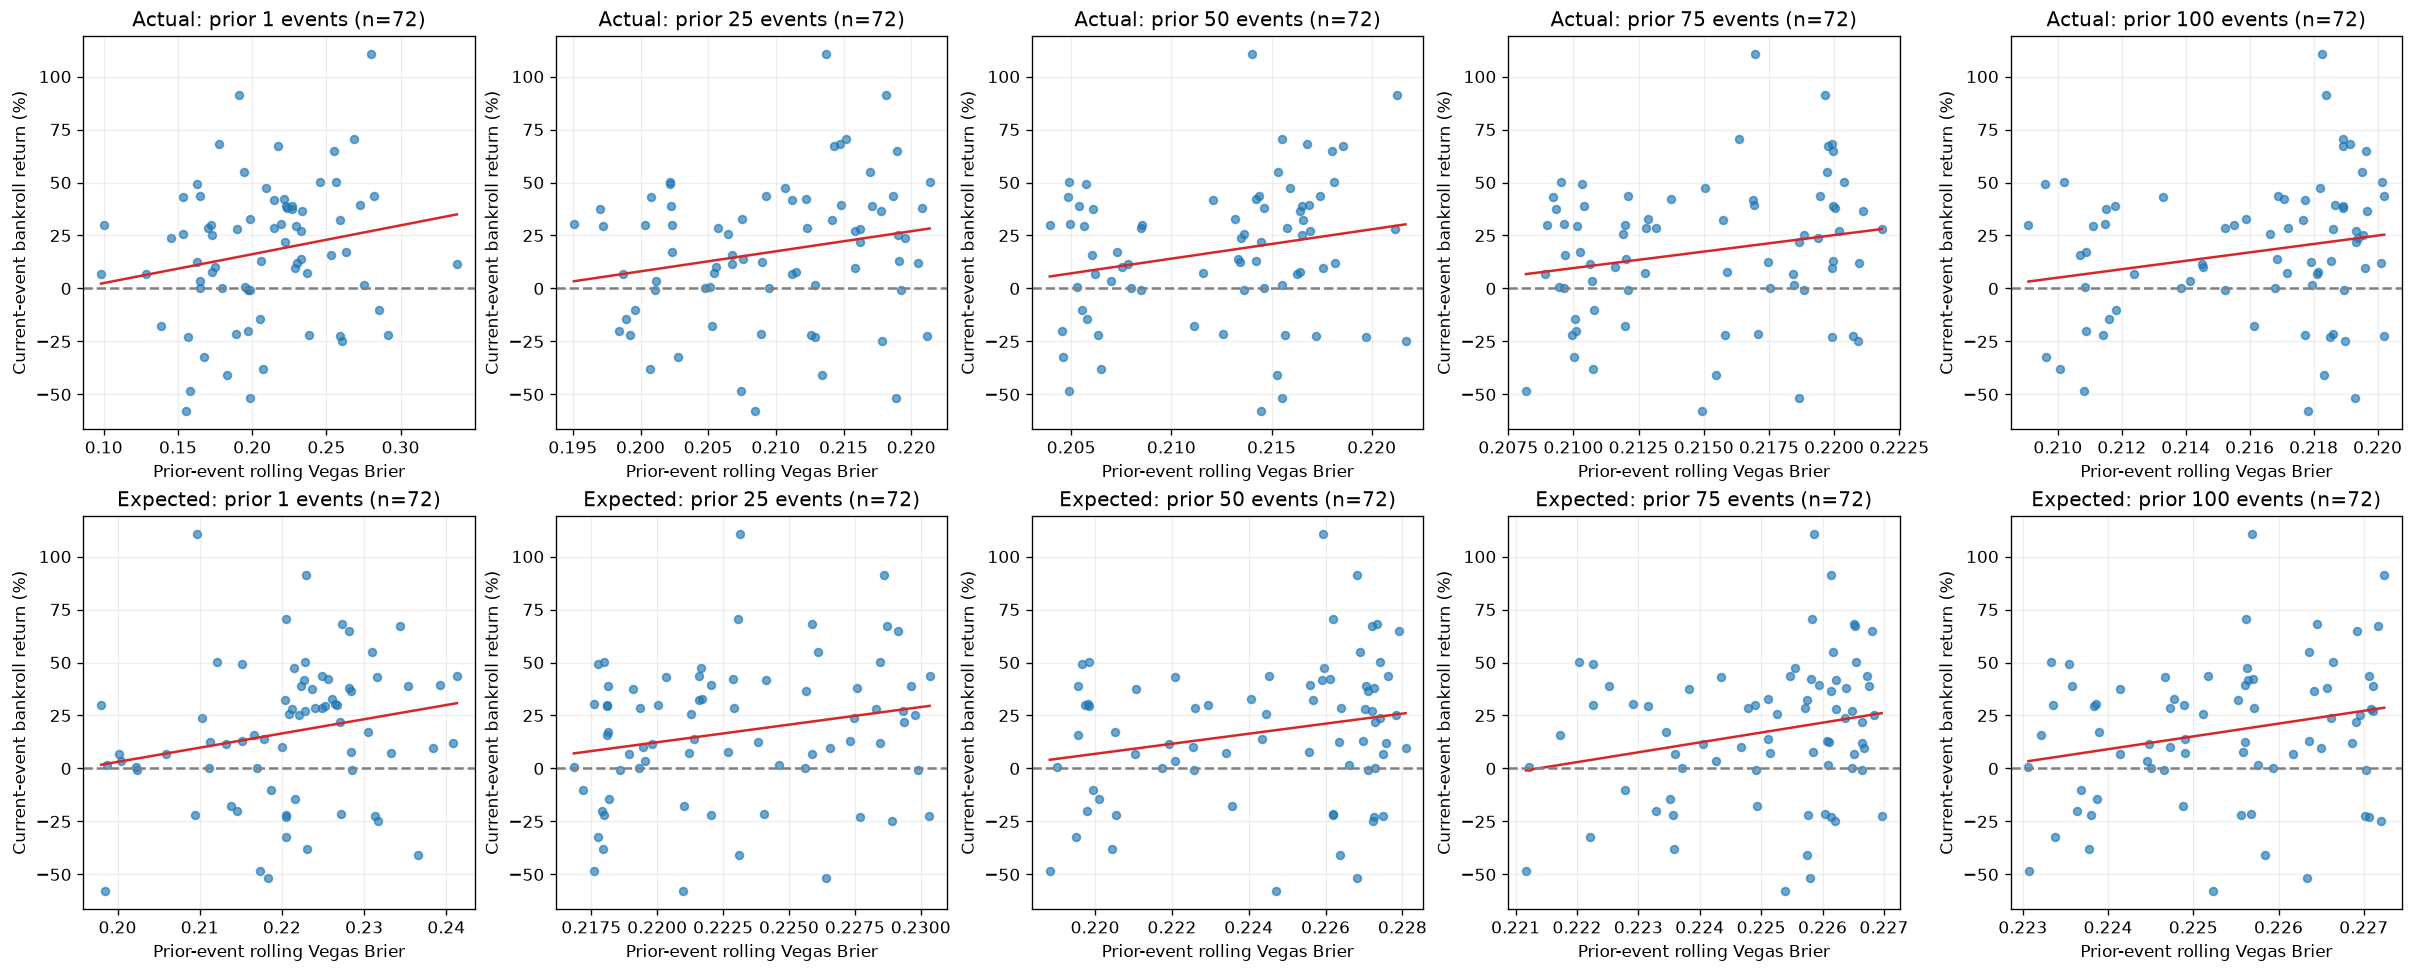

In [7]:
rng=np.random.default_rng(EVENT_CORRELATION_SEED)
records=[];prior_event_window_pairs={}
for measure in ('actual_vegas_brier','expected_vegas_brier'):
    for window in EVENT_WINDOWS:
        rolling=full_event_scores[measure].rolling(window,min_periods=window).mean().shift(1).reindex(event_brier_returns.index)
        paired=pd.DataFrame({'brier':rolling,'return_pct':event_brier_returns.return_pct}).dropna()
        prior_event_window_pairs[(measure,window)]=paired
        x=paired.brier.to_numpy();y=paired.return_pct.to_numpy()
        pearson=spearman=lo=hi=np.nan
        if len(paired)>=4 and np.std(x)>0 and np.std(y)>0:
            pearson=float(pearsonr(x,y).statistic);spearman=float(spearmanr(x,y).statistic)
            lo,hi=event_corr_ci(x,y,rng)
        records.append(dict(measure=measure,window_events=window,pairs=len(paired),Pearson=pearson,
                            Spearman=spearman,CI_low=lo,CI_high=hi))
prior_event_window_correlations=pd.DataFrame(records)
print('Prior-event windows: average events t-W through t-1, paired with return at event t. Current event excluded.')
print('Earlier training events seed the windows; all correlation returns are validation-only.')
print(prior_event_window_correlations.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
fig,axes=plt.subplots(2,len(EVENT_WINDOWS),figsize=(20,8),constrained_layout=True)
for row,measure in enumerate(('actual_vegas_brier','expected_vegas_brier')):
    for col,window in enumerate(EVENT_WINDOWS):
        ax=axes[row,col];sample=prior_event_window_pairs[(measure,window)]
        ax.scatter(sample.brier,sample.return_pct,alpha=.65,s=22)
        if len(sample)>=4 and sample.brier.std()>0:
            slope,intercept=np.polyfit(sample.brier,sample.return_pct,1)
            grid=np.linspace(sample.brier.min(),sample.brier.max(),100)
            ax.plot(grid,intercept+slope*grid,color='tab:red')
        ax.axhline(0,color='gray',linestyle='--')
        ax.set(title=f'{"Actual" if row==0 else "Expected"}: prior {window} events (n={len(sample)})',
               xlabel='Prior-event rolling Vegas Brier',ylabel='Current-event bankroll return (%)')
        ax.grid(alpha=.2)
plt.show()
